# Data cleaning appendix

This notebook takes our raw data files and turns them into the analysis-ready data set for the project:
**how NYC weather relates to the number and type of 311 service requests.**

**Raw inputs** (in the same folder as this notebook, not modified by this notebook):

| File | What it is |
|---|---|
| `311ServiceRequests.csv` | NYC 311 service requests, Jan 1, 2020 – Aug 31, 2026 (22.3M rows, 3.2 GB) |
| `CentralPark.csv` | NOAA daily weather, Central Park station |
| `JFK.csv` | NOAA daily weather, JFK Airport station |

**Outputs** (written to the `data/` folder):

| File | Contents |
|---|---|
| `data/CentralPark_clean.csv` | Cleaned Central Park weather, one row per day |
| `data/JFK_clean.csv` | Cleaned JFK weather, one row per day |
| `data/daily_complaints_weather.csv` | **Analysis-ready data set:** one row per day × complaint group, with complaint counts, calendar features and both stations' weather |

**Before running:** the raw 311 CSV is too big for GitHub, so the repository stores it as `311ServiceRequests.csv.zip` (via Git LFS). Unzip it in this folder first.

The **Data description** section (after the analysis-ready data set) describes the final data set.

**How to run:** run all cells from top to bottom. Reading the 3.2 GB 311 CSV takes a few minutes.

**Packages:** pandas and numpy.

## Data collection

### 311 service requests
- **Source:** NYC Open Data, *311 Service Requests* dataset: *311 Service Requests from 2020 to Present*.
- **How:** exported as a CSV from the NYC Open Data website (the dataset's Export option). No code was used to collect it.
- **Query:** requests created from Jan 1, 2020 through Aug 31, 2026. The created and closed dates were truncated to the
  day in the export (that is why the columns are named `by_day_created_date` / `by_day_closed_date` and every time is 12:00 AM). 
- **Columns kept:** Unique Key, created date, closed date, Agency, Problem (formerly Complaint Type),
  Problem Detail (formerly Descriptor), Additional Details, Location Type, Borough.
- **Downloaded:** September 8. The result is 22,335,555 rows (3.2 GB), stored in the repository zipped (`311ServiceRequests.csv.zip`, 250 MB) with Git LFS.

### Weather
- **Source:** NOAA National Centers for Environmental Information, Climate Data Online (CDO), *Daily Summaries* (GHCN-Daily).
- **Stations:** NY City Central Park (`USW00094728`) and JFK International Airport (`USW00094789`).
- **Dates:** Jan 1, 2020 – Sep 1, 2026, one row per day (2,436 days per station).
- **Downloaded:** September 8, as a CSV per station, with data flags included (the `_ATTRIBUTES` columns).
- Values come in GHCN's native units (tenths of °C, tenths of mm, mm, tenths of m/s), so they are converted below.
- **Why two stations:** Central Park is the standard reference station for NYC weather. JFK is used to fill gaps in
  Central Park's wind data and as a second, coastal measurement of the same days.

## Setup
Packages and file locations. All intermediate and output files go in the `data/` folder.

In [233]:
import os
import numpy as np
import pandas as pd
from pandas.tseries.holiday import USFederalHolidayCalendar

In [234]:
#Raw files (as downloaded, in the same folder as this notebook)
RAW_CP = "CentralPark.csv"
RAW_JFK = "JFK.csv"
RAW_311 = "311ServiceRequests.csv"

#Intermediate and output files
DATA_DIR = "data"
CLEAN_CP = os.path.join(DATA_DIR, "CentralPark_clean.csv")
CLEAN_JFK = os.path.join(DATA_DIR, "JFK_clean.csv")
FINAL_FILE = os.path.join(DATA_DIR, "daily_complaints_weather.csv")
os.makedirs(DATA_DIR, exist_ok=True)

ComplaintType = "Problem (formerly Complaint Type)"

## Weather data: Central Park
NOAA's file has one row per day and about 120 columns. Each measurement column (e.g. `TMAX`) has a matching
`_ATTRIBUTES` column with quality and source flags. The steps below keep the measurements we need, fill the few gaps,
convert units, and add calendar features.

In [235]:
#Load both weather files (the 311 data is loaded at the start of its own section)
CentralParkWeather = pd.read_csv(RAW_CP)
JFKWeather = pd.read_csv(RAW_JFK)

In [236]:
CentralParkWeather.head()

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES,...,WT17,WT17_ATTRIBUTES,WT18,WT18_ATTRIBUTES,WT19,WT19_ATTRIBUTES,WT21,WT21_ATTRIBUTES,WT22,WT22_ATTRIBUTES
0,USW00094728,2020-01-01,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,USW00094728,2020-01-02,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,USW00094728,2020-01-03,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",38,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,USW00094728,2020-01-04,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",69,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,USW00094728,2020-01-05,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0,"T,,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Missing values
Share of missing values in every column. Many columns are completely empty for this station.

In [237]:
#Looking for NaNs, nulls 
pd.set_option("display.max_rows", None)
summary = pd.DataFrame({
    "null_count": CentralParkWeather.isna().sum(),
    "null_pct": (CentralParkWeather.isna().mean() * 100).round(2),
}).sort_values("null_pct", ascending=False)

summary

,null_count,null_pct
WDF1,2436,100.00
MDWM_ATTRIBUTES,2436,100.00
WSFM,2436,100.00
WSFG_ATTRIBUTES,2436,100.00
WSFG,2436,100.00
WSF1_ATTRIBUTES,2436,100.00
WSF1,2436,100.00
WESD_ATTRIBUTES,2436,100.00
WESD,2436,100.00
WDMV_ATTRIBUTES,2436,100.00


### Dropping empty and unneeded columns
Columns that are 100% empty are dropped (with their `_ATTRIBUTES` partner). A few columns with some data are also dropped
by choice: sunshine minutes and peak-gust time (almost never recorded) and wind directions (not needed, and angles
can't be averaged normally). An `assert` confirms each "empty" column really is empty before dropping it.

In [238]:
#Initially, all of the attributes above that have a null percent of 100.00 will be dropped since they contain no data.
#A second group of columns that have some data, but not enough or not useful, is dropped as well.

# Each NOAA measurement column (e.g. "TAVG") has a matching "_ATTRIBUTES" column
# (e.g. "TAVG_ATTRIBUTES") with its flags, so each column is dropped together with its partner.

# ======================= PART 1: 100% NULL COLUMNS =======================

# --- Temperature ---
# TOBS (temperature at observation time)
# were never recorded. Compute average temperature later as (TMAX + TMIN) / 2.
temperature_cols = ["TOBS"]

# --- Cloud cover ---
# ACMH / ACSH: average cloudiness, midnight-to-midnight and sunrise-to-sunset.
cloud_cols = ["ACMH", "ACSH"]

# --- Sunshine ---
# PSUN: percent of possible sunshine.
sunshine_cols = ["PSUN"]

# --- Evaporation ---
# DAEV: number of days in a multi-day evaporation total
# MDEV: multi-day evaporation total
# EVAP: daily pan evaporation
evaporation_cols = ["DAEV", "MDEV", "EVAP"]

# --- Multi-day snowfall and wind totals ---
# DASF / MDSF: number of days and total for multi-day snowfall
# DAWM / MDWM: number of days and total for multi-day wind movement
multiday_cols = ["DASF", "MDSF", "DAWM", "MDWM"]

# --- Wind ---
# FMTM: time of the fastest mile or fastest 1-minute wind
# WDF1 / WSF1: direction and speed of the fastest 1-minute wind
# WDFG / WSFG: direction and speed of the peak gust
# WDFM / WSFM: direction and speed of the fastest mile
# WDMV: 24-hour wind movement
wind_cols = ["FMTM", "WDF1", "WSF1", "WDFG", "WSFG", "WDFM", "WSFM", "WDMV"]

# --- Snow water equivalent ---
# WESD: water equivalent of snow on the ground.
snow_water_cols = ["WESD"]

# --- Weather-type flags ---
# A WT** column holds 1 on days the event happened and is blank otherwise.
# These were never flagged at this station, so they carry no information.
#   WT07 dust/sand          WT11 high winds       WT13 mist
#   WT14 drizzle            WT15 freezing drizzle WT16 rain
#   WT17 freezing rain      WT18 snow             WT19 unknown precipitation
#   WT21 ground fog         WT22 ice fog
weather_type_cols = ["WT07", "WT11", "WT13", "WT14", "WT15", "WT16",
                     "WT17", "WT18", "WT19", "WT21", "WT22"]

empty_measurements = (temperature_cols + cloud_cols + sunshine_cols +
                      evaporation_cols + multiday_cols + wind_cols +
                      snow_water_cols + weather_type_cols)

# ============== PART 2: COLUMNS WITH SOME DATA, DROPPED BY CHOICE ==============

# --- Nearly empty ---
# TSUN: daily minutes of sunshine. Only 2 of 2,436 days have a value (both 0).
# PGTM: time of day of the peak gust. Only recorded on 69 days (2024-2025),
#       and a time of day is not useful for comparing against daily 311 counts.
nearly_empty_cols = ["TSUN", "PGTM"]

# --- Wind direction ---
# WDF2 / WDF5: direction of the fastest 2-minute and 5-second wind (degrees).
# Not needed for this analysis, and directions are angles that cannot be averaged
# normally (the average of 350 and 10 degrees is 0, not 180).
wind_direction_cols = ["WDF2", "WDF5"]


chosen_measurements = nearly_empty_cols + wind_direction_cols

# ============================ DROP BOTH GROUPS ============================

# --- Safety check: confirm every Part 1 column is really 100% null before dropping ---
empty_to_drop = empty_measurements + [c + "_ATTRIBUTES" for c in empty_measurements]
not_empty = [c for c in empty_to_drop if CentralParkWeather[c].notna().any()]
assert not not_empty, f"These columns contain data and should not be dropped: {not_empty}"

chosen_to_drop = chosen_measurements + [c + "_ATTRIBUTES" for c in chosen_measurements]
cols_to_drop = empty_to_drop + chosen_to_drop

CentralParkWeather = CentralParkWeather.drop(columns=cols_to_drop)

print(f"Dropped {len(cols_to_drop)} columns; {CentralParkWeather.shape[1]} remain.")

Dropped 70 columns; 54 remain.


### Filling missing wind speeds from JFK
Central Park's wind sensor has gaps (mostly May 18 – Jun 18, 2020 and Sep – Oct 2021). Those days are filled from JFK
using a straight-line fit between the two stations (JFK is much windier, so its raw values are not copied directly).
Real Central Park readings are never changed. `WIND_FILLED_FROM_JFK` = 1 marks the filled days.

In [239]:
#Filling Central Park's missing wind speeds from JFK
#Central Park's wind sensor has gaps (mostly May 18 - Jun 18, 2020 and Sep - Oct 2021). JFK has wind data on all of those days.
#Only the days where Central Park has NO value are filled; every real Central Park reading is kept.
#NOTE: JFK is much windier than Central Park (open coastal airport vs. a park sheltered by trees and buildings),
#so JFK's raw values are NOT copied in directly. Instead, a straight-line fit between the two stations (built from
#days where both have data) converts each JFK value to what Central Park would likely have recorded.
#This runs BEFORE the unit conversion, so filled values are whole numbers in tenths of m/s, exactly like the original
#data, and then get converted to mph along with everything else.
#The only way to tell a filled day from a real reading is WIND_FILLED_FROM_JFK (1 = filled, 0 = real Central Park reading).
WindCols = ["AWND", "WSF2", "WSF5"]

#---Pull JFK's wind, lined up day-by-day with Central Park (both still in raw tenths of m/s)---
JFKWind = JFKWeather.set_index("DATE")[WindCols].reindex(CentralParkWeather["DATE"]).reset_index(drop=True)

#---Mark which days are being filled (any of the three wind columns missing)---
CentralParkWeather["WIND_FILLED_FROM_JFK"] = CentralParkWeather[WindCols].isna().any(axis=1).astype(int)

#---Fill each wind column---
for col in WindCols:
    Both = CentralParkWeather[col].notna() & JFKWind[col].notna()
    slope, intercept = np.polyfit(JFKWind.loc[Both, col], CentralParkWeather.loc[Both, col], 1)
    Estimate = (slope * JFKWind[col] + intercept).round(0)   #whole numbers, matching the raw data
    Missing = CentralParkWeather[col].isna()
    CentralParkWeather.loc[Missing, col] = Estimate[Missing]
    print(f"{col}: filled {Missing.sum()} days | Central Park ≈ {slope:.2f} × JFK {intercept:+.2f} (tenths of m/s)")

CentralParkWeather.loc[CentralParkWeather["WIND_FILLED_FROM_JFK"] == 1, ["DATE"] + WindCols].head()

AWND: filled 60 days | Central Park ≈ 0.46 × JFK -0.82 (tenths of m/s)
WSF2: filled 55 days | Central Park ≈ 0.45 × JFK +17.83 (tenths of m/s)
WSF5: filled 66 days | Central Park ≈ 0.64 × JFK +22.00 (tenths of m/s)


,DATE,AWND,WSF2,WSF5
21,2020-01-22,7.0,38.0,59.0
22,2020-01-23,13.0,42.0,59.0
23,2020-01-24,11.0,44.0,68.0
24,2020-01-25,34.0,84.0,150.0
25,2020-01-26,27.0,64.0,101.0


### Unit conversions
Temperature: tenths of °C → °F. Precipitation: tenths of mm → inches. Snowfall and snow depth: mm → inches
(the 4 days with no snow depth are all in spring or summer, so they are set to 0). Wind: tenths of m/s → mph.

In [240]:
#Conversion of data into readable formats
#Many of the data points (including temperature and wind speed) are stored as whole numbers in the metric system

#---Temperature---
#Temperature is currently in tenths of Degrees Celsius
#Math: Divide by 10, multiply by 9/5, add 32
CentralParkWeather["TMAX"] = (((CentralParkWeather["TMAX"]*9)/10)/5)+32
CentralParkWeather["TMIN"] = (((CentralParkWeather["TMIN"]*9)/10)/5)+32

#---Rain Fall ---
#Rainfall is currently in tenths of millimeters and must be converted to inches
#Math: Divide by 10, then divide by 25.40
CentralParkWeather["PRCP"] = (CentralParkWeather["PRCP"]/10)/25.4

#---Snow Fall---
#Snowfall is currently in whole millimeters and must be converted to inches
#Math: Dividy by 25.4
CentralParkWeather["SNOW"] = CentralParkWeather["SNOW"]/25.4
CentralParkWeather["SNWD"] = CentralParkWeather["SNWD"]/25.4
CentralParkWeather["SNWD"] = CentralParkWeather["SNWD"].fillna(0)

#---Wind Speed---
#Wind is currently in Tenths of m/s and will be converted to mph
#Math: Divide by 10 then multiply by 2.23694
CentralParkWeather["AWND"] = CentralParkWeather["AWND"]/10*2.23694
CentralParkWeather["WSF2"] = CentralParkWeather["WSF2"]/10*2.23694
CentralParkWeather["WSF5"] = CentralParkWeather["WSF5"]/10*2.23694

### Average temperature
The `TAVG` column is empty in the raw file, so it is calculated as (TMAX + TMIN) / 2.

In [241]:
#Making the TAVG Column#
#The TAVG (Average Temperature) in the original dataset is empty so it will be created here
#Math: TAVG = (TMAX + TMIN)/2
CentralParkWeather["TAVG"] = (CentralParkWeather["TMAX"] + CentralParkWeather["TMIN"]) /2
CentralParkWeather["TAVG"].head()

0    37.49
1    41.00
2    46.49
3    46.04
4    38.57
Name: TAVG, dtype: float64

### Trace amounts
A "T" flag in the `_ATTRIBUTES` column means a trace amount: rain or snow too small to measure, recorded as 0.
This is kept as a 0/1 `_TRACE` column so the flag columns can be removed.

In [242]:
#Adding a trace column
#For some attribute columns like snow and rain, there are times where there are light amounts of either, but a small enough amount where it would round to 0
#To be able to remove the attribute columns, trace amounts will be moved into a new column
Attributes = [c for c in CentralParkWeather.columns if c.endswith("_ATTRIBUTES")]
for col in Attributes:
    is_trace = CentralParkWeather[col].fillna("").astype(str).str.split(",").str[0].eq("T")
    if is_trace.any():
        measurement = col.replace("_ATTRIBUTES", "")
        position = CentralParkWeather.columns.get_loc(measurement) + 1
        CentralParkWeather.insert(position, measurement + "_TRACE", is_trace.astype(int))


CentralParkWeather.head()


,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_TRACE,PRCP_ATTRIBUTES,SNOW,...,WT04_ATTRIBUTES,WT05,WT05_ATTRIBUTES,WT06,WT06_ATTRIBUTES,WT08,WT08_ATTRIBUTES,WT09,WT09_ATTRIBUTES,WIND_FILLED_FROM_JFK
0,USW00094728,2020-01-01,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,USW00094728,2020-01-02,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,USW00094728,2020-01-03,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.149606,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,1.0,",,W",NaN,NaN,0
3,USW00094728,2020-01-04,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.271654,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,USW00094728,2020-01-05,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,1,"T,,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


### Removing flag columns
With trace amounts saved, the `_ATTRIBUTES` columns carry nothing else we need.

In [243]:
#Removing all attribute columns
#The Trace data pulled into a separate column in the previous cell was the only relevant data from the attribtue columns. Therefore we are going to remove all of the attribute columns
CentralParkWeather = CentralParkWeather.drop(columns=CentralParkWeather.filter(like="_ATTRIBUTES").columns)

### Removing humidity and pressure
Humidity, dew point, wet-bulb temperature and pressure stop at the end of 2024, so they are removed. This rules out
questions like "hot and humid vs. hot and dry".

In [244]:
#Removing data with severely limited data
#For all columns relating to humidity and pressure, all data stops in 2024. Therefore we will remove this data
#Risks: This does prevent some analysis, for example, are there more 311 complaints when it is hot and humid versus hot and dry. 
#Columns being removed: RHAV: average relative humidity; RHMN: minimum relative humidity; RHMX: maximum relative humidity; ADPT: average dew point temperature; AWBT: average wet-bulb temperature; ASLP: average sea-level pressure; ASTP: average station-level pressure
ColumnsWithLimitedData = ["RHAV", "RHMN", "RHMX", "ADPT", "AWBT", "ASLP", "ASTP"]
CentralParkWeather = CentralParkWeather.drop(columns=ColumnsWithLimitedData)

### Weather-type flags
The `WT01`–`WT22` codes are renamed to readable names (e.g. `WT03` → `WT_THUNDER`). Blank means the event did not
happen, so blanks become 0.

In [245]:
#Adding rich labels for "WT" Columns
#WT has 22 columns, WT01 through WT22
#To prevent needing to look through a data dictionary, these will be given labels that are more descriptive
#Additionally, many of these columns are fully empty in both sets of weather data and have already been removed by this point
weather_type_names = {
    "WT01": "WT_FOG",                  # Fog, ice fog, or freezing fog (may include heavy fog)
    "WT02": "WT_HEAVY_FOG",            # Heavy fog or heavy freezing fog
    "WT03": "WT_THUNDER",              # Thunder
    "WT04": "WT_ICE_PELLETS_SLEET",    # Ice pellets, sleet, snow pellets, or small hail
    "WT05": "WT_HAIL",                 # Hail (may include small hail)
    "WT06": "WT_GLAZE_RIME",           # Glaze or rime
    "WT07": "WT_DUST_SAND",            # Dust, volcanic ash, blowing dust/sand, or blowing obstruction
    "WT08": "WT_SMOKE_HAZE",           # Smoke or haze
    "WT09": "WT_BLOWING_SNOW",         # Blowing or drifting snow
    "WT10": "WT_TORNADO",              # Tornado, waterspout, or funnel cloud
    "WT11": "WT_HIGH_WINDS",           # High or damaging winds
    "WT12": "WT_BLOWING_SPRAY",        # Blowing spray
    "WT13": "WT_MIST",                 # Mist
    "WT14": "WT_DRIZZLE",              # Drizzle
    "WT15": "WT_FREEZING_DRIZZLE",     # Freezing drizzle
    "WT16": "WT_RAIN",                 # Rain (may include freezing rain, drizzle, freezing drizzle)
    "WT17": "WT_FREEZING_RAIN",        # Freezing rain
    "WT18": "WT_SNOW",                 # Snow, snow pellets, snow grains, or ice crystals
    "WT19": "WT_UNKNOWN_PRECIP",       # Unknown source of precipitation
    "WT21": "WT_GROUND_FOG",           # Ground fog
    "WT22": "WT_ICE_FOG",              # Ice fog or freezing fog
}
CentralParkWeather = CentralParkWeather.rename(columns=weather_type_names)



#All remaining WT events will also be given a value of 0 where there is currently no entry. 
#Currently, an empty cell for a WT column means that the weather event did not happen, this step formalizes it for analysis purposes
WTCols = [c for c in CentralParkWeather.columns if c.startswith("WT_")]
CentralParkWeather[WTCols] = CentralParkWeather[WTCols].fillna(0).astype(int)
CentralParkWeather.head()

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_TRACE,SNOW,SNOW_TRACE,...,WSF5,WT_FOG,WT_HEAVY_FOG,WT_THUNDER,WT_ICE_PELLETS_SLEET,WT_HAIL,WT_GLAZE_RIME,WT_SMOKE_HAZE,WT_BLOWING_SNOW,WIND_FILLED_FROM_JFK
0,USW00094728,2020-01-01,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,0,0.0,0,...,29.080220,0,0,0,0,0,0,0,0,0
1,USW00094728,2020-01-02,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,0,0.0,0,...,21.922012,0,0,0,0,0,0,0,0,0
2,USW00094728,2020-01-03,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.149606,0,0.0,0,...,14.987498,1,0,0,0,0,0,1,0,0
3,USW00094728,2020-01-04,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.271654,0,0.0,0,...,23.935258,1,1,0,0,0,0,0,0,0
4,USW00094728,2020-01-05,40.77898,-73.96925,42.7,"NY CITY CENTRAL PARK, NY US",0.000000,1,0.0,0,...,42.949248,0,0,0,0,0,0,0,0,0


### Calendar features
Year, month, day of week, weekend, meteorological season and federal holidays (observed days) are added. 311 volume
depends strongly on these, so the analysis needs them as controls.

In [246]:
#Adding rich date
#Similar to how a relational database has an entire dimension dedicated to dates so analysis can be done by specific time features, additional date

#Converting DATE from text to a date datatype
CentralParkWeather["DATE"] = pd.to_datetime(CentralParkWeather["DATE"])
Dates = CentralParkWeather["DATE"]

#Calendar Parts
DateFeatures = pd.DataFrame({
    "YEAR": Dates.dt.year,
    "MONTH": Dates.dt.month, #1=January, 12=December, etc. 
    "MONTH_NAME": Dates.dt.month_name(),
    "DAY": Dates.dt.day,
    "DAY_OF_YEAR": Dates.dt.dayofyear, #Days 1-366
    "WEEK_OF_YEAR": Dates.dt.isocalendar().week.astype(int),
    "DAY_OF_WEEK": Dates.dt.dayofweek,  #0 = Monday ... 6 = Sunday
    "DAY_NAME": Dates.dt.day_name(),
})

#Weekend Flag
DateFeatures["IS_WEEKEND"] = (DateFeatures["DAY_OF_WEEK"] >= 5).astype(int)

#Season
#Meteorological seasons (whole months): Dec-Feb winter, Mar-May spring, Jun-Aug summer, Sep-Nov fall
SeasonByMonth = {12: "Winter", 1: "Winter", 2: "Winter",
                 3: "Spring", 4: "Spring", 5: "Spring",
                 6: "Summer", 7: "Summer", 8: "Summer",
                 9: "Fall", 10: "Fall", 11: "Fall"}
DateFeatures["SEASON"] = DateFeatures["MONTH"].map(SeasonByMonth)

#Federal holidays
#When a holiday falls on a weekend, the observed day off (Friday or Monday) is flagged
Holidays = USFederalHolidayCalendar().holidays(start=Dates.min(), end=Dates.max())
DateFeatures["IS_HOLIDAY"] = Dates.isin(Holidays).astype(int)

#Insert the new columns right after DATE
Position = CentralParkWeather.columns.get_loc("DATE") + 1
for i, col in enumerate(DateFeatures.columns):
    CentralParkWeather.insert(Position + i, col, DateFeatures[col])

CentralParkWeather[["DATE"] + list(DateFeatures.columns)].head(10)

,DATE,YEAR,MONTH,MONTH_NAME,DAY,DAY_OF_YEAR,WEEK_OF_YEAR,DAY_OF_WEEK,DAY_NAME,IS_WEEKEND,SEASON,IS_HOLIDAY
0,2020-01-01,2020,1,January,1,1,1,2,Wednesday,0,Winter,1
1,2020-01-02,2020,1,January,2,2,1,3,Thursday,0,Winter,0
2,2020-01-03,2020,1,January,3,3,1,4,Friday,0,Winter,0
3,2020-01-04,2020,1,January,4,4,1,5,Saturday,1,Winter,0
4,2020-01-05,2020,1,January,5,5,1,6,Sunday,1,Winter,0
5,2020-01-06,2020,1,January,6,6,2,0,Monday,0,Winter,0
6,2020-01-07,2020,1,January,7,7,2,1,Tuesday,0,Winter,0
7,2020-01-08,2020,1,January,8,8,2,2,Wednesday,0,Winter,0
8,2020-01-09,2020,1,January,9,9,2,3,Thursday,0,Winter,0
9,2020-01-10,2020,1,January,10,10,2,4,Friday,0,Winter,0


### Checks
Each check prints PASS or FAIL. Known events (Hurricane Ida, the Feb 1, 2021 snowstorm, the hottest day) confirm the
unit conversions.

In [247]:
#Code Tests, AI written tests to ensure that all cleaning measures are working properly
#Sanity check
#Confirms the cleaning steps above worked. Each check prints PASS or FAIL so problems are easy to spot.
#Known events are used to confirm the unit conversions are correct.
def check(description, condition):
    print(("PASS  " if condition else "FAIL  ") + description)

def value_on(date, column):
    return CentralParkWeather.loc[CentralParkWeather["DATE"] == date, column].item()

#---Dates---
FullRange = pd.date_range(CentralParkWeather["DATE"].min(), CentralParkWeather["DATE"].max())
check("DATE is a datetime column", pd.api.types.is_datetime64_any_dtype(CentralParkWeather["DATE"]))
check("No missing days", len(FullRange.difference(CentralParkWeather["DATE"])) == 0)
check("No duplicate days", not CentralParkWeather["DATE"].duplicated().any())
check("2020-01-01 is a Wednesday", value_on("2020-01-01", "DAY_NAME") == "Wednesday")
#July 4, 2020 fell on a Saturday, so the holiday was observed (offices closed) on Friday July 3
check("2020-07-03 is a holiday (Independence Day, observed)", value_on("2020-07-03", "IS_HOLIDAY") == 1)
#10-12 per year: Juneteenth was added in 2021, and New Year's 2022 was observed on Dec 31, 2021
check("10-12 federal holidays per full year",
      CentralParkWeather[CentralParkWeather["YEAR"] < 2026].groupby("YEAR")["IS_HOLIDAY"].sum().between(10, 12).all())

#---Temperature (should now be in °F)---
check("2020-01-01 TAVG is about 37.5 °F", abs(value_on("2020-01-01", "TAVG") - 37.5) < 0.1)
check("Hottest day is about 100 °F", abs(CentralParkWeather["TMAX"].max() - 100.0) < 0.5)
check("All temperatures between -10 and 110 °F",
      CentralParkWeather[["TMAX", "TMIN"]].stack().between(-10, 110).all())
check("TMIN is never above TMAX", (CentralParkWeather["TMIN"] <= CentralParkWeather["TMAX"]).all())
check("TAVG sits between TMIN and TMAX",
      CentralParkWeather["TAVG"].between(CentralParkWeather["TMIN"], CentralParkWeather["TMAX"]).all())

#---Precipitation and snow (should now be in inches)---
check("Hurricane Ida (2021-09-01) rainfall is about 7.13 in", abs(value_on("2021-09-01", "PRCP") - 7.13) < 0.01)
check("2021-02-01 snowstorm is about 14.8 in", abs(value_on("2021-02-01", "SNOW") - 14.8) < 0.1)
check("No negative precipitation or snow", (CentralParkWeather[["PRCP", "SNOW", "SNWD"]].stack() >= 0).all())

#---Wind (should now be in mph)---
check("Average wind between 0 and 40 mph", CentralParkWeather["AWND"].dropna().between(0, 40).all())
BothWind = CentralParkWeather[["AWND", "WSF5"]].dropna()   #only compare days where both were recorded
check("Gusts are at least as fast as average wind", (BothWind["WSF5"] >= BothWind["AWND"]).all())

check("No missing wind speeds", CentralParkWeather[["AWND", "WSF2", "WSF5"]].notna().all().all())

#---Trace and weather-type columns---
TraceCols = [c for c in CentralParkWeather.columns if c.endswith("_TRACE")]
WTCols = [c for c in CentralParkWeather.columns if c.startswith("WT_")]
check(f"Trace columns exist: {TraceCols}", len(TraceCols) == 3)
check("Trace and WT columns only contain 0 or 1",
      CentralParkWeather[TraceCols + WTCols].isin([0, 1]).all().all())
check("Trace days always have a measured value of 0",
      all((CentralParkWeather.loc[CentralParkWeather[c] == 1, c.replace("_TRACE", "")] == 0).all() for c in TraceCols))

#---Removed columns---
check("No _ATTRIBUTES columns remain", not any(c.endswith("_ATTRIBUTES") for c in CentralParkWeather.columns))
check("Humidity/pressure columns removed",
      not any(c in CentralParkWeather.columns for c in ["RHAV", "RHMN", "RHMX", "ADPT", "AWBT", "ASLP", "ASTP"]))
check("No fully empty columns remain", not CentralParkWeather.isna().all().any())

#---Remaining missing values (not necessarily errors, but should be known)---
print("\nColumns that still have missing values:")
print(CentralParkWeather.isna().sum()[lambda s: s > 0])


PASS  DATE is a datetime column
PASS  No missing days
PASS  No duplicate days
PASS  2020-01-01 is a Wednesday
PASS  2020-07-03 is a holiday (Independence Day, observed)
PASS  10-12 federal holidays per full year
PASS  2020-01-01 TAVG is about 37.5 °F
PASS  Hottest day is about 100 °F
PASS  All temperatures between -10 and 110 °F
PASS  TMIN is never above TMAX
PASS  TAVG sits between TMIN and TMAX
PASS  Hurricane Ida (2021-09-01) rainfall is about 7.13 in
PASS  2021-02-01 snowstorm is about 14.8 in
PASS  No negative precipitation or snow
PASS  Average wind between 0 and 40 mph
PASS  Gusts are at least as fast as average wind
PASS  No missing wind speeds
PASS  Trace columns exist: ['PRCP_TRACE', 'SNOW_TRACE', 'SNWD_TRACE']
PASS  Trace and WT columns only contain 0 or 1
PASS  Trace days always have a measured value of 0
PASS  No _ATTRIBUTES columns remain
PASS  Humidity/pressure columns removed
PASS  No fully empty columns remain

Columns that still have missing values:
Series([], dtype: 

### Save cleaned Central Park weather

In [248]:
CentralParkWeather.to_csv(CLEAN_CP, index=False)
print(f"Saved {CLEAN_CP}: {CentralParkWeather.shape[0]:,} rows, {CentralParkWeather.shape[1]} columns")

Saved data/CentralPark_clean.csv: 2,436 rows, 38 columns


## Weather data: JFK
The JFK file goes through the same steps as Central Park. The differences are:
- JFK has a slightly different set of columns, so it has its own list of empty columns to drop.
- JFK's wind data is almost complete. Only the 5-second gust (`WSF5`) is missing, on 6 days, and those are filled from
  Central Park with the same straight-line method. `WIND_FILLED_FROM_CP` = 1 marks them.
- The checks use JFK's own values for the known events.

In [249]:
JFKWeather.head()

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES,...,WT18,WT18_ATTRIBUTES,WT19,WT19_ATTRIBUTES,WT21,WT21_ATTRIBUTES,WT22,WT22_ATTRIBUTES,WV01,WV01_ATTRIBUTES
0,USW00094789,2020-01-01,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,USW00094789,2020-01-02,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,USW00094789,2020-01-03,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",33,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,USW00094789,2020-01-04,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",41,",,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,USW00094789,2020-01-05,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0,"T,,W,2400",0,",,W,2400",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Missing values

In [250]:
#Looking for NaNs, nulls 
pd.set_option("display.max_rows", None)
summary = pd.DataFrame({
    "null_count": JFKWeather.isna().sum(),
    "null_pct": (JFKWeather.isna().mean() * 100).round(2),
}).sort_values("null_pct", ascending=False)

summary

,null_count,null_pct
WDFG_ATTRIBUTES,2436,100.00
WT11_ATTRIBUTES,2436,100.00
WT07_ATTRIBUTES,2436,100.00
WT07,2436,100.00
WSFM_ATTRIBUTES,2436,100.00
WSFM,2436,100.00
WSFG_ATTRIBUTES,2436,100.00
WSFG,2436,100.00
WSF1_ATTRIBUTES,2436,100.00
WSF1,2436,100.00


### Dropping empty and unneeded columns

In [251]:
#JFK: dropping empty and unneeded columns
#JFK's columns are not the same as Central Park's, so it has its own explicit list.
#Each NOAA measurement column (e.g. "TSUN") has a matching "_ATTRIBUTES" column
#(e.g. "TSUN_ATTRIBUTES") with its flags, so each column is dropped together with its partner.

# ======================= PART 1: 100% NULL COLUMNS =======================

# --- Cloud cover ---
# ACMH / ACSH: average cloudiness, midnight-to-midnight and sunrise-to-sunset.
JFK_cloud_cols = ["ACMH", "ACSH"]

# --- Sunshine ---
# TSUN: daily total minutes of sunshine. (Central Park had 2 values; JFK has none.)
JFK_sunshine_cols = ["TSUN"]

# --- Multi-day precipitation (only exists in the JFK file) ---
# DAPR: number of days included in a multi-day precipitation total
# MDPR: multi-day precipitation total
JFK_multiday_cols = ["DAPR", "MDPR"]

# --- Wind ---
# FMTM: time of the fastest mile or fastest 1-minute wind
# WDF1 / WSF1: direction and speed of the fastest 1-minute wind
# WDFG / WSFG: direction and speed of the peak gust
# WDFM / WSFM: direction and speed of the fastest mile
JFK_wind_cols = ["FMTM", "WDF1", "WSF1", "WDFG", "WSFG", "WDFM", "WSFM"]

# --- Snow water equivalent ---
# WESD: water equivalent of snow on the ground.
JFK_snow_water_cols = ["WESD"]

# --- Weather-type flags ---
# A WT** column holds 1 on days the event happened and is blank otherwise.
# These were never flagged at this station, so they carry no information.
#   WT07 dust/sand          WT11 high winds       WT13 mist
#   WT14 drizzle            WT15 freezing drizzle WT16 rain
#   WT17 freezing rain      WT18 snow             WT19 unknown precipitation
#   WT21 ground fog         WT22 ice fog
JFK_weather_type_cols = ["WT07", "WT11", "WT13", "WT14", "WT15", "WT16",
                         "WT17", "WT18", "WT19", "WT21", "WT22"]

# --- Weather in the vicinity (only exists in the JFK file) ---
# WV01: fog, ice fog, or freezing fog near (but not at) the station.
JFK_vicinity_cols = ["WV01"]

# TAVG is also 100% null but is NOT dropped here: it is recalculated from TMAX and TMIN later.

JFK_empty_measurements = (JFK_cloud_cols + JFK_sunshine_cols + JFK_multiday_cols +
                          JFK_wind_cols + JFK_snow_water_cols + JFK_weather_type_cols +
                          JFK_vicinity_cols)

# ============== PART 2: COLUMNS WITH SOME DATA, DROPPED BY CHOICE ==============

# --- Nearly empty ---
# PGTM: time of day of the peak gust. Only recorded on 69 of 2,436 days (2024-2025),
#       and a time of day is not useful for comparing against daily 311 counts.
JFK_nearly_empty_cols = ["PGTM"]

# --- Wind direction ---
# WDF2 / WDF5: direction of the fastest 2-minute and 5-second wind (degrees).
# Not needed for this analysis, and directions are angles that cannot be averaged
# normally (the average of 350 and 10 degrees is 0, not 180).
JFK_wind_direction_cols = ["WDF2", "WDF5"]

JFK_chosen_measurements = JFK_nearly_empty_cols + JFK_wind_direction_cols

# ============================ DROP BOTH GROUPS ============================

# --- Safety check: confirm every Part 1 column is really 100% null before dropping ---
JFK_empty_to_drop = JFK_empty_measurements + [c + "_ATTRIBUTES" for c in JFK_empty_measurements]
JFK_not_empty = [c for c in JFK_empty_to_drop if JFKWeather[c].notna().any()]
assert not JFK_not_empty, f"These columns contain data and should not be dropped: {JFK_not_empty}"

JFK_chosen_to_drop = JFK_chosen_measurements + [c + "_ATTRIBUTES" for c in JFK_chosen_measurements]
JFK_cols_to_drop = JFK_empty_to_drop + JFK_chosen_to_drop

JFKWeather = JFKWeather.drop(columns=JFK_cols_to_drop)

print(f"Dropped {len(JFK_cols_to_drop)} columns; {JFKWeather.shape[1]} remain.")

Dropped 56 columns; 54 remain.


### Filling missing gusts from Central Park

In [252]:
#Filling JFK's missing 5-second gusts from Central Park
#JFK's AWND and WSF2 are complete. WSF5 is missing 6 days (2020-06-30, 2020-07-29, 2020-09-08 to 09-10, 2026-07-01),
#and Central Park has real readings on all of them.
#Same method as Central Park's fill: a straight-line fit between the stations, done in raw tenths of m/s and rounded
#to whole numbers so filled values look like the original data.
#The only way to tell a filled day apart is WIND_FILLED_FROM_CP (1 = filled, 0 = real JFK reading).
CentralParkRaw = pd.read_csv(RAW_CP)
CPWind = CentralParkRaw.set_index("DATE")["WSF5"].reindex(JFKWeather["DATE"]).reset_index(drop=True)

JFKWeather["WIND_FILLED_FROM_CP"] = JFKWeather["WSF5"].isna().astype(int)

Both = JFKWeather["WSF5"].notna() & CPWind.notna()
slope, intercept = np.polyfit(CPWind[Both], JFKWeather.loc[Both, "WSF5"], 1)
Estimate = (slope * CPWind + intercept).round(0)
Missing = JFKWeather["WSF5"].isna()
JFKWeather.loc[Missing, "WSF5"] = Estimate[Missing]
print(f"WSF5: filled {Missing.sum()} days | JFK ≈ {slope:.2f} × Central Park {intercept:+.2f} (tenths of m/s)")

WSF5: filled 6 days | JFK ≈ 1.05 × Central Park +19.73 (tenths of m/s)


### Same steps as Central Park
Unit conversions, average temperature, trace amounts, removing flag, humidity and pressure columns, weather-type names
and calendar features.

In [253]:
#Conversion of data into readable formats
#Many of the data points (including temperature and wind speed) are stored as whole numbers in the metric system

#---Temperature---
#Temperature is currently in tenths of Degrees Celcius
#Math: Divide by 10, multiply by 9/5, add 32
JFKWeather["TMAX"] = (((JFKWeather["TMAX"]*9)/10)/5)+32
JFKWeather["TMIN"] = (((JFKWeather["TMIN"]*9)/10)/5)+32

#---Rain Fall ---
#Rainfall is currently in tenths of millimeters and must be converted to inches
#Math: Divide by 10, then divide by 25.40
JFKWeather["PRCP"] = (JFKWeather["PRCP"]/10)/25.4

#---Snow Fall---
#Snowfall is currently in whole millimeters and must be converted to inches
#Math: Dividy by 25.4
JFKWeather["SNOW"] = JFKWeather["SNOW"]/25.4
JFKWeather["SNWD"] = JFKWeather["SNWD"]/25.4
JFKWeather["SNWD"] = JFKWeather["SNWD"].fillna(0)

#---Wind Speed---
#Wind is currently in Tenths of m/s and will be converted to mph
#Math: Divide by 10 then multiply by 2.23694
JFKWeather["AWND"] = JFKWeather["AWND"]/10*2.23694
JFKWeather["WSF2"] = JFKWeather["WSF2"]/10*2.23694
JFKWeather["WSF5"] = JFKWeather["WSF5"]/10*2.23694

In [254]:
#Making the TAVG Column#
#The TAVG (Average Temperature) in the original dataset is empty so it will be created here
#Math: TAVG = (TMAX + TMIN)/2
JFKWeather["TAVG"] = (JFKWeather["TMAX"] + JFKWeather["TMIN"]) /2
JFKWeather["TAVG"].head()

0    38.03
1    39.56
2    45.05
3    47.03
4    41.99
Name: TAVG, dtype: float64

In [255]:
#Adding a trace column
#For some attribute columns like snow and rain, there are times where there are light amounts of either, but a small enough amount where it would round to 0
#To be able to remove the attribute columns, trace amounts will be moved into a new column
Attributes = [c for c in JFKWeather.columns if c.endswith("_ATTRIBUTES")]
for col in Attributes:
    is_trace = JFKWeather[col].fillna("").astype(str).str.split(",").str[0].eq("T")
    if is_trace.any():
        measurement = col.replace("_ATTRIBUTES", "")
        position = JFKWeather.columns.get_loc(measurement) + 1
        JFKWeather.insert(position, measurement + "_TRACE", is_trace.astype(int))


JFKWeather.head()


,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_TRACE,PRCP_ATTRIBUTES,SNOW,...,WT04_ATTRIBUTES,WT05,WT05_ATTRIBUTES,WT06,WT06_ATTRIBUTES,WT08,WT08_ATTRIBUTES,WT09,WT09_ATTRIBUTES,WIND_FILLED_FROM_CP
0,USW00094789,2020-01-01,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,USW00094789,2020-01-02,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,USW00094789,2020-01-03,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.129921,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,USW00094789,2020-01-04,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.161417,0,",,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,USW00094789,2020-01-05,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,1,"T,,W,2400",0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [256]:
#Removing all attribute columns
#The Trace data pulled into a separate column in the previous cell was the only relevant data from the attribute columns. Therefore we are going to remove all of the attribute columns
JFKWeather = JFKWeather.drop(columns=JFKWeather.filter(like="_ATTRIBUTES").columns)

In [257]:
#Removing data with severely limited data
#For all columns relating to humidity and pressure, all data stops in 2024. Therefore we will remove this data
#Risks: This does prevent some analysis, for example, are there more 311 complaints when it is hot and humid versus hot and dry. 
#Columns being removed: RHAV: average relative humidity; RHMN: minimum relative humidity; RHMX: maximum relative humidity; ADPT: average dew point temperature; AWBT: average wet-bulb temperature; ASLP: average sea-level pressure; ASTP: average station-level pressure
ColumnsWithLimitedData = ["RHAV", "RHMN", "RHMX", "ADPT", "AWBT", "ASLP", "ASTP"]
JFKWeather = JFKWeather.drop(columns=ColumnsWithLimitedData)

In [258]:
#Adding rich labels for "WT" Columns
#WT has 22 columns, WT01 through WT22
#To prevent needing to look through a data dictionary, these will be given labels that are more descriptive
#Additionally, many of these columns are fully empty in both sets of weather data and have already been removed by this point
weather_type_names = {
    "WT01": "WT_FOG",                  # Fog, ice fog, or freezing fog (may include heavy fog)
    "WT02": "WT_HEAVY_FOG",            # Heavy fog or heavy freezing fog
    "WT03": "WT_THUNDER",              # Thunder
    "WT04": "WT_ICE_PELLETS_SLEET",    # Ice pellets, sleet, snow pellets, or small hail
    "WT05": "WT_HAIL",                 # Hail (may include small hail)
    "WT06": "WT_GLAZE_RIME",           # Glaze or rime
    "WT07": "WT_DUST_SAND",            # Dust, volcanic ash, blowing dust/sand, or blowing obstruction
    "WT08": "WT_SMOKE_HAZE",           # Smoke or haze
    "WT09": "WT_BLOWING_SNOW",         # Blowing or drifting snow
    "WT10": "WT_TORNADO",              # Tornado, waterspout, or funnel cloud
    "WT11": "WT_HIGH_WINDS",           # High or damaging winds
    "WT12": "WT_BLOWING_SPRAY",        # Blowing spray
    "WT13": "WT_MIST",                 # Mist
    "WT14": "WT_DRIZZLE",              # Drizzle
    "WT15": "WT_FREEZING_DRIZZLE",     # Freezing drizzle
    "WT16": "WT_RAIN",                 # Rain (may include freezing rain, drizzle, freezing drizzle)
    "WT17": "WT_FREEZING_RAIN",        # Freezing rain
    "WT18": "WT_SNOW",                 # Snow, snow pellets, snow grains, or ice crystals
    "WT19": "WT_UNKNOWN_PRECIP",       # Unknown source of precipitation
    "WT21": "WT_GROUND_FOG",           # Ground fog
    "WT22": "WT_ICE_FOG",              # Ice fog or freezing fog
}
JFKWeather = JFKWeather.rename(columns=weather_type_names)



#All remaining WT events will also be given a value of 0 where there is currently no entry. 
#Currently, an empty cell for a WT column means that the weather event did not happen, this step formalizes it for analysis purposes
WTCols = [c for c in JFKWeather.columns if c.startswith("WT_")]
JFKWeather[WTCols] = JFKWeather[WTCols].fillna(0).astype(int)
JFKWeather.head()

,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_TRACE,SNOW,SNOW_TRACE,...,WSF5,WT_FOG,WT_HEAVY_FOG,WT_THUNDER,WT_ICE_PELLETS_SLEET,WT_HAIL,WT_GLAZE_RIME,WT_SMOKE_HAZE,WT_BLOWING_SNOW,WIND_FILLED_FROM_CP
0,USW00094789,2020-01-01,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,0,0.0,0,...,38.922756,0,0,0,0,0,0,0,0,0
1,USW00094789,2020-01-02,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,0,0.0,0,...,21.922012,0,0,0,0,0,0,0,0,0
2,USW00094789,2020-01-03,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.129921,0,0.0,0,...,16.105968,1,0,0,0,0,0,0,0,0
3,USW00094789,2020-01-04,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.161417,0,0.0,0,...,35.119958,1,1,0,0,0,0,0,0,0
4,USW00094789,2020-01-05,40.63915,-73.7639,2.7,"JFK INTERNATIONAL AIRPORT, NY US",0.000000,1,0.0,0,...,51.002232,0,0,0,0,0,0,0,0,0


In [259]:
#Adding rich date
#Similar to how a relational database has an entire dimension dedicated to dates so analysis can be done by specific time features, additional date

#Converting DATE from text to a date datatype
JFKWeather["DATE"] = pd.to_datetime(JFKWeather["DATE"])
Dates = JFKWeather["DATE"]

#Calendar Parts
DateFeatures = pd.DataFrame({
    "YEAR": Dates.dt.year,
    "MONTH": Dates.dt.month, #1=January, 12=December, etc. 
    "MONTH_NAME": Dates.dt.month_name(),
    "DAY": Dates.dt.day,
    "DAY_OF_YEAR": Dates.dt.dayofyear, #Days 1-366
    "WEEK_OF_YEAR": Dates.dt.isocalendar().week.astype(int),
    "DAY_OF_WEEK": Dates.dt.dayofweek,  #0 = Monday ... 6 = Sunday
    "DAY_NAME": Dates.dt.day_name(),
})

#Weekend Flag
DateFeatures["IS_WEEKEND"] = (DateFeatures["DAY_OF_WEEK"] >= 5).astype(int)

#Season
#Meteorological seasons (whole months): Dec-Feb winter, Mar-May spring, Jun-Aug summer, Sep-Nov fall
SeasonByMonth = {12: "Winter", 1: "Winter", 2: "Winter",
                 3: "Spring", 4: "Spring", 5: "Spring",
                 6: "Summer", 7: "Summer", 8: "Summer",
                 9: "Fall", 10: "Fall", 11: "Fall"}
DateFeatures["SEASON"] = DateFeatures["MONTH"].map(SeasonByMonth)

#Federal holidays
#When a holiday falls on a weekend, the observed day off (Friday or Monday) is flagged
Holidays = USFederalHolidayCalendar().holidays(start=Dates.min(), end=Dates.max())
DateFeatures["IS_HOLIDAY"] = Dates.isin(Holidays).astype(int)

#Insert the new columns right after DATE
Position = JFKWeather.columns.get_loc("DATE") + 1
for i, col in enumerate(DateFeatures.columns):
    JFKWeather.insert(Position + i, col, DateFeatures[col])

JFKWeather[["DATE"] + list(DateFeatures.columns)].head(10)

,DATE,YEAR,MONTH,MONTH_NAME,DAY,DAY_OF_YEAR,WEEK_OF_YEAR,DAY_OF_WEEK,DAY_NAME,IS_WEEKEND,SEASON,IS_HOLIDAY
0,2020-01-01,2020,1,January,1,1,1,2,Wednesday,0,Winter,1
1,2020-01-02,2020,1,January,2,2,1,3,Thursday,0,Winter,0
2,2020-01-03,2020,1,January,3,3,1,4,Friday,0,Winter,0
3,2020-01-04,2020,1,January,4,4,1,5,Saturday,1,Winter,0
4,2020-01-05,2020,1,January,5,5,1,6,Sunday,1,Winter,0
5,2020-01-06,2020,1,January,6,6,2,0,Monday,0,Winter,0
6,2020-01-07,2020,1,January,7,7,2,1,Tuesday,0,Winter,0
7,2020-01-08,2020,1,January,8,8,2,2,Wednesday,0,Winter,0
8,2020-01-09,2020,1,January,9,9,2,3,Thursday,0,Winter,0
9,2020-01-10,2020,1,January,10,10,2,4,Friday,0,Winter,0


### Checks

In [260]:
#Code Tests, AI written tests to ensure that all cleaning measures are working properly
#Sanity check
#Confirms the cleaning steps above worked. Each check prints PASS or FAIL so problems are easy to spot.
#Known events are used to confirm the unit conversions are correct.
def check(description, condition):
    print(("PASS  " if condition else "FAIL  ") + description)

def value_on(date, column):
    return JFKWeather.loc[JFKWeather["DATE"] == date, column].item()

#---Dates---
FullRange = pd.date_range(JFKWeather["DATE"].min(), JFKWeather["DATE"].max())
check("DATE is a datetime column", pd.api.types.is_datetime64_any_dtype(JFKWeather["DATE"]))
check("No missing days", len(FullRange.difference(JFKWeather["DATE"])) == 0)
check("No duplicate days", not JFKWeather["DATE"].duplicated().any())
check("2020-01-01 is a Wednesday", value_on("2020-01-01", "DAY_NAME") == "Wednesday")
#July 4, 2020 fell on a Saturday, so the holiday was observed (offices closed) on Friday July 3
check("2020-07-03 is a holiday (Independence Day, observed)", value_on("2020-07-03", "IS_HOLIDAY") == 1)
#10-12 per year: Juneteenth was added in 2021, and New Year's 2022 was observed on Dec 31, 2021
check("10-12 federal holidays per full year",
      JFKWeather[JFKWeather["YEAR"] < 2026].groupby("YEAR")["IS_HOLIDAY"].sum().between(10, 12).all())

#---Temperature (should now be in °F)---
check("2020-01-01 TAVG is about 38.0 °F", abs(value_on("2020-01-01", "TAVG") - 38.0) < 0.1)
check("Hottest day (2025-06-24) is about 102 °F", abs(JFKWeather["TMAX"].max() - 102.0) < 0.5)
check("All temperatures between -10 and 110 °F",
      JFKWeather[["TMAX", "TMIN"]].stack().between(-10, 110).all())
check("TMIN is never above TMAX", (JFKWeather["TMIN"] <= JFKWeather["TMAX"]).all())
check("TAVG sits between TMIN and TMAX",
      JFKWeather["TAVG"].between(JFKWeather["TMIN"], JFKWeather["TMAX"]).all())

#---Precipitation and snow (should now be in inches)---
check("Hurricane Ida (2021-09-01) rainfall is about 2.56 in", abs(value_on("2021-09-01", "PRCP") - 2.56) < 0.01)
check("2021-02-01 snowstorm is about 11.9 in", abs(value_on("2021-02-01", "SNOW") - 11.9) < 0.1)
check("No negative precipitation or snow", (JFKWeather[["PRCP", "SNOW", "SNWD"]].stack() >= 0).all())

#---Wind (should now be in mph)---
check("Average wind between 0 and 40 mph", JFKWeather["AWND"].dropna().between(0, 40).all())
BothWind = JFKWeather[["AWND", "WSF5"]].dropna()   #only compare days where both were recorded
check("Gusts are at least as fast as average wind", (BothWind["WSF5"] >= BothWind["AWND"]).all())

check("No missing wind speeds", JFKWeather[["AWND", "WSF2", "WSF5"]].notna().all().all())

#---Trace and weather-type columns---
TraceCols = [c for c in JFKWeather.columns if c.endswith("_TRACE")]
WTCols = [c for c in JFKWeather.columns if c.startswith("WT_")]
check(f"Trace columns exist: {TraceCols}", len(TraceCols) == 3)
check("Trace and WT columns only contain 0 or 1",
      JFKWeather[TraceCols + WTCols].isin([0, 1]).all().all())
check("Trace days always have a measured value of 0",
      all((JFKWeather.loc[JFKWeather[c] == 1, c.replace("_TRACE", "")] == 0).all() for c in TraceCols))

#---Removed columns---
check("No _ATTRIBUTES columns remain", not any(c.endswith("_ATTRIBUTES") for c in JFKWeather.columns))
check("Humidity/pressure columns removed",
      not any(c in JFKWeather.columns for c in ["RHAV", "RHMN", "RHMX", "ADPT", "AWBT", "ASLP", "ASTP"]))
check("No fully empty columns remain", not JFKWeather.isna().all().any())

#---Remaining missing values (not necessarily errors, but should be known)---
print("\nColumns that still have missing values:")
print(JFKWeather.isna().sum()[lambda s: s > 0])

PASS  DATE is a datetime column
PASS  No missing days
PASS  No duplicate days
PASS  2020-01-01 is a Wednesday
PASS  2020-07-03 is a holiday (Independence Day, observed)
PASS  10-12 federal holidays per full year
PASS  2020-01-01 TAVG is about 38.0 °F
PASS  Hottest day (2025-06-24) is about 102 °F
PASS  All temperatures between -10 and 110 °F
PASS  TMIN is never above TMAX
PASS  TAVG sits between TMIN and TMAX
PASS  Hurricane Ida (2021-09-01) rainfall is about 2.56 in
PASS  2021-02-01 snowstorm is about 11.9 in
PASS  No negative precipitation or snow
PASS  Average wind between 0 and 40 mph
PASS  Gusts are at least as fast as average wind
PASS  No missing wind speeds
PASS  Trace columns exist: ['PRCP_TRACE', 'SNOW_TRACE', 'SNWD_TRACE']
PASS  Trace and WT columns only contain 0 or 1
PASS  Trace days always have a measured value of 0
PASS  No _ATTRIBUTES columns remain
PASS  Humidity/pressure columns removed
PASS  No fully empty columns remain

Columns that still have missing values:
Serie

### Save cleaned JFK weather

In [261]:
JFKWeather.to_csv(CLEAN_JFK, index=False)
print(f"Saved {CLEAN_JFK}: {JFKWeather.shape[0]:,} rows, {JFKWeather.shape[1]} columns")

Saved data/JFK_clean.csv: 2,436 rows, 38 columns


## 311 service requests

### Overview of the 311 cleaning

**Granularity.** Every timestamp is midnight, so the data can only be analyzed by day. Dates are parsed with `format="%Y %b %d %I:%M:%S %p"`.

**Complaint types**
1. *Spelling duplicates.* 17 types appear twice with different capitalization or punctuation (e.g. `HEAT/HOT WATER` vs `Heat/Hot Water`). Most mixed-case HPD versions only exist Aug 10 – Oct 6, 2023 (a temporary relabel). Each is mapped to its most common spelling.
2. *Renamed types.* Some labels stop on the day their replacement starts. Without merging, the old type looks like it drops to zero. Main ones: `Snow` / `Snow Removal` → `Snow or Ice`, and the Sept 21, 2021 DSNY relabel (Dirty Conditions, Missed Collection, Litter/Recycling Baskets, Sweeping, Vacant Lot, Derelict Bicycle).
3. *COVID-only types.* Phased-reopening, mass-gathering, face-covering and vaccine-mandate complaints only exist in 2020–2023. They are moved out of `Complaints` into `CovidComplaints` so they don't inflate those years.
4. *Complaint groups.* There are ~250 types after merging, many with under 100 rows. Each type is assigned to one `COMPLAINT_GROUP` (Heat/Hot Water, Noise, Flooding/Sewer/Water, Snow/Ice, Trees, Street Condition, Housing Conditions, Sanitation, Other) for the weather analysis.

**Other columns**
5. *Borough.* 78,952 rows (0.35%) are blank or "Unspecified". They are labeled "Unspecified" and kept for citywide counts; filter them out only for borough-level analysis.
6. *Agency.* DCA → DCWP (Aug 2020), DOITT → OTI (Jan 2022). The system codes `3-1-1` and `NYC311-PRD` are mapped to the agency that handles those complaints (NYPD, DOT).
7. *Location type.* 226 messy labels are collapsed into ~15 categories; blanks become "Unknown".
8. *Closed dates (only for resolution time).* Some closed dates are missing, impossible (1899, 1900, 2004, 2019, 2033) or before the created date. These rows stay in `Complaints` (they are still real complaints) but are left out of `ResolutionTimes`.

**Things to keep in mind for the analysis**
- 311 runs Jan 1, 2020 – Aug 31, 2026; the weather runs one day longer. The join is on the 311 date, so the extra weather day is ignored.
- 2026 is a partial year, and Fall appears 6 times vs 7 for the other seasons, so compare **complaints per day**, not totals.
- Volume has a strong weekly cycle, dips on holidays, and an upward trend (≈2.9M rows in 2020 vs ≈3.7M in 2025). Control for weekday, holiday, season and year before reading any weather effect.

### Loading the raw 311 data
Reading the 3.2 GB CSV takes a few minutes.

In [262]:
Complaints = pd.read_csv(RAW_311)
print(f"{len(Complaints):,} rows, {Complaints.shape[1]} columns")

22,335,555 rows, 9 columns


In [263]:
Complaints.head()

,Unique Key,by_day_created_date,by_day_closed_date,Agency,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Additional Details,Location Type,Borough
0,40287734,2020 Sep 25 12:00:00 AM,2020 Sep 25 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Gate,Park,BRONX
1,40935119,2020 Sep 25 12:00:00 AM,2020 Sep 25 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Other,Park,BRONX
2,40962915,2020 Sep 25 12:00:00 AM,2020 Sep 25 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Gate,Park,BRONX
3,41499422,2020 Sep 24 12:00:00 AM,2020 Sep 24 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Sign,Park,BRONX
4,41680133,2020 Sep 25 12:00:00 AM,2020 Sep 25 12:00:00 AM,DPR,Maintenance or Facility,Structure - Outdoors,Playground Equipment,Park,BRONX


### Dates
The dates are text like "2020 Sep 25 12:00:00 AM" and are converted to datetimes.

In [264]:
#Converting the created and closed dates from text to a date datatype
#The dates are text like "2020 Sep 25 12:00:00 AM". Every time is 12:00 AM, so they line up with the weather's DATE column
Complaints["by_day_created_date"] = pd.to_datetime(Complaints["by_day_created_date"], format="%Y %b %d %I:%M:%S %p")
Complaints["by_day_closed_date"] = pd.to_datetime(Complaints["by_day_closed_date"], format="%Y %b %d %I:%M:%S %p")

### Merging spelling duplicates
17 complaint types appear under two spellings that differ only by capitalization or punctuation. Each is mapped to the
spelling with the most rows.

In [265]:
#Merging complaint types that differ only by capitalization/punctuation
#17 complaint types appear under two spellings. Most of the mixed-case HPD versions only exist
#from Aug 10 to Oct 6, 2023 (a temporary relabel)
#Each wrong spelling is mapped to the spelling with the most rows (row counts shown in the comments)
ComplaintType = "Problem (formerly Complaint Type)"

SpellingFixes = {
    #Capitalization Differences
    "Heat/Hot Water":            "HEAT/HOT WATER",             # 1,814  -> 1,649,748
    "Unsanitary Condition":      "UNSANITARY CONDITION",       # 1,263  -> 697,437
    "Plumbing":                  "PLUMBING",                   # 21,810 -> 402,360
    "Paint/Plaster":             "PAINT/PLASTER",              # 2,187  -> 366,397
    "Door/Window":               "DOOR/WINDOW",                # 1,258  -> 274,725
    "Water Leak":                "WATER LEAK",                 # 3,077  -> 253,642
    "General":                   "GENERAL",                    # 635    -> 196,842
    "Electric":                  "ELECTRIC",                   # 289    -> 179,400
    "Flooring/Stairs":           "FLOORING/STAIRS",            # 695    -> 161,470
    "Appliance":                 "APPLIANCE",                  # 559    -> 135,489
    "ELEVATOR":                  "Elevator",                   # 11,342 -> 122,156
    "Safety":                    "SAFETY",                     # 309    -> 74,945
    "ASBESTOS":                  "Asbestos",                   # 1      -> 9,347
    "Outside Building":          "OUTSIDE BUILDING",           # 2      -> 6,300
    "MOLD":                      "Mold",                       # 1      -> 2,137
    #Punctuation Differences
    "Litter Basket / Request":   "Litter Basket Request",      # 3,950  -> 18,098
    "Building Marshals office":  "Building Marshal's Office",  # 17     -> 24
}


#Applying the changes
RowsBefore = len(Complaints)
TypesBefore = Complaints[ComplaintType].nunique()
RowsChanged = Complaints[ComplaintType].isin(SpellingFixes.keys()).sum()
Complaints[ComplaintType] = Complaints[ComplaintType].replace(SpellingFixes)

#Checks
assert len(Complaints) == RowsBefore, "row count changed"
assert not Complaints[ComplaintType].isin(SpellingFixes.keys()).any(), "a wrong spelling is still present"
print(f"Rows relabeled: {RowsChanged:,}")
print(f"Complaint types: {TypesBefore} -> {Complaints[ComplaintType].nunique()}")




Rows relabeled: 49,209
Complaint types: 276 -> 259


### Merging renamed complaint types
When 311 renamed a type, the old name stops on the day the new one starts. Merging them keeps each type's daily
count continuous.

In [266]:
#Merging complaint types that were renamed
#311 renamed some complaint types partway through the data. The old name stops on the day the new one starts, so without merging, a complaint would look like it dropped to zero on the rename date.
#Most of the renames happened on Sept 21, 2021, when DSNY (Sanitation) relabeled its complaints.
#("Litter Basket / Request" is not listed here because the spelling fix above already handled it.)
RenamedTypes = {
    "Snow": "Snow or Ice",                                       #ends Mar 2021, Snow or Ice starts Oct 2021
    "Snow Removal": "Snow or Ice",                               #ends Feb 2021
    "Dirty Conditions": "Dirty Condition",                       #ends Sept 21, 2021
    "Missed Collection (All Materials)": "Missed Collection",    #ends Sept 21, 2021
    "Overflowing Litter Baskets": "Litter Basket Complaint",     #ends Sept 21, 2021
    "Overflowing Recycling Baskets": "Recycling Basket Complaint", #ends Sept 15, 2021, new name starts Oct 18, 2021
    "Derelict Bicycle": "Abandoned Bike",                        #ends Sept 21, 2021
    "Sweeping/Missed": "Street Sweeping Complaint",              #ends Sept 20, 2021
    "Sweeping/Inadequate": "Street Sweeping Complaint",          #ends Sept 20, 2021
    "Sweeping/Missed-Inadequate": "Street Sweeping Complaint",   #ends June 2021
    "Vacant Lot": "Lot Condition",                               #ends Sept 21, 2021
    "Smoking": "Smoking or Vaping",                              #ends Nov 17, 2024 (Smoking or Vaping starts Dec 3, 2023, so they overlap for a year)
    "Bike/Roller/Skate Chronic": "Bike/Roller/Skate",            #ends Nov 12, 2025, new name starts Nov 13
    "Hazardous Materials": "Hazardous Material",                 #DEP relabel, ends July 2026
}
Complaints[ComplaintType] = Complaints[ComplaintType].replace(RenamedTypes)
print(f"Complaint types after merging renames: {Complaints[ComplaintType].nunique()}")

Complaint types after merging renames: 245


### Removing COVID-only complaint types
Seven types only exist during the pandemic. They are moved to a separate table (`CovidComplaints`) so they don't
inflate the 2020–2023 totals.

In [267]:
#Removing COVID-only complaint types
#These types only exist during the pandemic (roughly 2020-2023), so they would inflate the totals for those years
#and make it look like complaints dropped afterwards. They are moved into their own table instead of being deleted,
#so they can still be looked at separately.
CovidTypes = [
    "NonCompliance with Phased Reopening",              #Jun 2020 - Jul 2021
    "COVID-19 Non-essential Construction",              #Mar 2020 - Mar 2022
    "Vaccine Mandate Non-Compliance",                   #Aug 2021 - Sep 2022
    "Private School Vaccine Mandate Non-Compliance",    #Dec 2021 - Jan 2023
    "Face Covering Violation",                          #Dec 2021 - Jun 2023
    "Mass Gathering Complaint",                         #Oct 2020 - Feb 2022
    "Private or Charter School Reopening",              #Oct 2020 - Mar 2022
]
#Catch typos: every name in the list must exist in the data
assert set(CovidTypes) <= set(Complaints[ComplaintType].unique()), "a COVID type name is misspelled"

IsCovid = Complaints[ComplaintType].isin(CovidTypes)
CovidComplaints = Complaints[IsCovid].copy()
Complaints = Complaints.drop(index=Complaints.index[IsCovid])   #drop() avoids a SettingWithCopyWarning later

print(f"COVID-only complaints moved to CovidComplaints: {len(CovidComplaints):,}")
print(f"Complaints remaining: {len(Complaints):,}")
CovidComplaints[ComplaintType].value_counts()

COVID-only complaints moved to CovidComplaints: 88,809
Complaints remaining: 22,246,746


Problem (formerly Complaint Type)
NonCompliance with Phased Reopening              66317
Vaccine Mandate Non-Compliance                    7399
COVID-19 Non-essential Construction               7322
Mass Gathering Complaint                          3652
Private or Charter School Reopening               2101
Face Covering Violation                           1799
Private School Vaccine Mandate Non-Compliance      219
Name: count, dtype: int64

### Complaint groups
About 245 types remain, too many to compare with the weather one by one. Each type is assigned to one
`COMPLAINT_GROUP`: Heat/Hot Water, Noise, Flooding/Sewer/Water, Snow/Ice, Trees, Street Condition, Housing Conditions,
Sanitation, or Other. The code comments explain the less obvious choices.

In [268]:
#Grouping complaint types for the weather analysis
#There are about 250 complaint types, too many to compare against the weather one by one.
#Each type is assigned to one broad group. Types that are not weather-related (or too small to matter) go to "Other".
#Notes on some choices:
#   - Water System -> Water Maintenance and Sewer -> Sewer Maintenance were relabeled by DEP at the end of July 2026.
#     The old and new names are kept as separate types (the new ones also existed before), but they are in the same
#     group, so the group's daily count is not affected by the relabel.
#   - WATER LEAK (indoor leaks reported to HPD) is in Housing Conditions, not Flooding. It may still rise after heavy rain.
#   - New Tree Request is in Other: it is a request to plant a tree, not storm damage.
#   - "Other" contains its own breaks (e.g. Request Large Bulky Item Collection ends Sep 2022), so don't analyze "Other" as a whole.
ComplaintGroups = {
    "Heat/Hot Water": ["HEAT/HOT WATER", "Boilers", "Boiler", "Non-Residential Heat"],
    "Flooding/Sewer/Water": ["Sewer", "Sewer Maintenance", "Water System", "Water Maintenance", "Standing Water",
                             "Storm", "Water Drainage", "Indoor Sewage", "Green Infrastructure", "Dry Weather Discharge"],
    "Snow/Ice": ["Snow or Ice"],
    "Trees": ["Damaged Tree", "Overgrown Tree/Branches", "Dead/Dying Tree", "Illegal Tree Damage", "Uprooted Stump",
              "Wood Pile Remaining", "Root/Sewer/Sidewalk Condition"],
    "Street Condition": ["Street Condition", "Sidewalk Condition", "Curb Condition", "Highway Condition",
                         "Bridge Condition", "Tunnel Condition", "DEP Street Condition", "DEP Highway Condition",
                         "DEP Sidewalk Condition", "DEP Bridge Condition", "Street Light Condition",
                         "Traffic Signal Condition", "Street Sign - Damaged", "Street Sign - Missing",
                         "Street Sign - Dangling", "Highway Sign - Damaged", "Highway Sign - Missing",
                         "Highway Sign - Dangling"],
    "Housing Conditions": ["UNSANITARY CONDITION", "PLUMBING", "PAINT/PLASTER", "DOOR/WINDOW", "WATER LEAK", "GENERAL",
                           "ELECTRIC", "FLOORING/STAIRS", "APPLIANCE", "SAFETY", "Elevator", "Mold",
                           "OUTSIDE BUILDING", "Unstable Building"],
    "Sanitation": ["Dirty Condition", "Missed Collection", "Illegal Dumping", "Sanitation Condition", "Obstruction",
                   "Litter Basket Complaint", "Litter Basket Request", "Residential Disposal Complaint",
                   "Commercial Disposal Complaint", "Institution Disposal Complaint", "Street Sweeping Complaint",
                   "Dumpster Complaint"],
}

#Flip the groups into a type -> group lookup
GroupMap = {t: group for group, types in ComplaintGroups.items() for t in types}

#Every noise type starts with "Noise" (Noise - Residential, Noise - Street/Sidewalk, ...), plus one sanitation noise type
AllTypes = Complaints[ComplaintType].unique()
for t in AllTypes:
    if t.startswith("Noise") or t == "Collection Truck Noise":
        GroupMap[t] = "Noise"

#Catch typos: every listed type must exist in the data (after the spelling fixes and renames above)
Missing = sorted(set(GroupMap) - set(AllTypes))
assert not Missing, f"These group types are not in the data: {Missing}"

Complaints["COMPLAINT_GROUP"] = Complaints[ComplaintType].map(GroupMap).fillna("Other")

#Rows per group, and the biggest types left in "Other" (to check nothing weather-related was missed)
print(Complaints["COMPLAINT_GROUP"].value_counts().to_string())
print("\nLargest types in Other:")
print(Complaints.loc[Complaints["COMPLAINT_GROUP"] == "Other", ComplaintType].value_counts().head(15).to_string())

COMPLAINT_GROUP
Other                   8702270
Noise                   5088206
Housing Conditions      2916812
Heat/Hot Water          1679642
Street Condition        1415274
Sanitation              1150746
Flooding/Sewer/Water     651612
Trees                    546766
Snow/Ice                  95418

Largest types in Other:
Problem (formerly Complaint Type)
Illegal Parking                        2893399
Blocked Driveway                       1065058
Request Large Bulky Item Collection     632148
Abandoned Vehicle                       398196
Derelict Vehicles                       291726
General Construction/Plumbing           245610
Rodent                                  238473
Homeless Person Assistance              235409
Encampment                              226412
Non-Emergency Police Matter             206551
Consumer Complaint                      152328
Maintenance or Facility                 142887
Building/Use                            130583
Illegal Fireworks         

### Unknown boroughs
Blank boroughs are labeled "Unspecified". These rows are kept for citywide counts and only filtered out for
borough-level analysis.

In [269]:
#Handling unknown boroughs
#78,952 requests (0.35%) have no usable borough: 40,519 say "Unspecified" and 38,433 are blank.
#The blanks are labeled "Unspecified" too, so there is one label for unknown boroughs.
#These rows are kept because they still count toward the citywide totals. They are only removed for borough-level analysis.
Complaints["Borough"] = Complaints["Borough"].fillna("Unspecified")
#For borough-level analysis, filter at that point instead of keeping a second full copy of the data, e.g.
#   ByBorough = ComplaintsWeather[ComplaintsWeather["Borough"] != "Unspecified"]

### Agency names
Renamed agencies are merged under their current names, and two system codes are replaced with the real agency.

In [270]:
#Standardizing agency names
#Two agencies were renamed partway through the data, so they are merged under their current names:
#   DCA (Consumer Affairs) became DCWP (Consumer and Worker Protection) in Aug 2020
#   DOITT (Information Technology) became OTI (Technology and Innovation) in Jan 2022
#Two agency labels are system codes instead of real agencies. They are changed to the agency
#that handles those complaint types everywhere else in the data:
#   "3-1-1" (1 row, Noise - Commercial) is always handled by NYPD
#   "NYC311-PRD" (371 rows, street/sidewalk/curb conditions, Mar-Apr 2026) is always handled by DOT
RenamedAgencies = {
    "DCA": "DCWP",
    "DOITT": "OTI",
    "3-1-1": "NYPD",
    "NYC311-PRD": "DOT",
}
Complaints["Agency"] = Complaints["Agency"].replace(RenamedAgencies)

### Location types
226 inconsistent labels are collapsed into about 15 categories. Blank and unclear labels become "Unknown".

In [271]:
#Cleaning up location types
#The raw column has 226 different labels for about a dozen kinds of places. The same place is often spelled several ways
#("RESIDENTIAL BUILDING", "Residential Building/House", "3+ Family Apt.", "3+Family Apt.", ...), some are typos ("Comercial"),
#and some are internal codes ("AD3", "NR4") or complaint types typed into the wrong field ("Abandoned Bike").
#Each label is assigned to one broad category below. Codes, typos with no clear meaning, and "Other"/"Unknown" go to "Unknown".
LocationGroups = {
    "Residential": [
        "RESIDENTIAL BUILDING", "Residential Building/House", "Residential Building", "Residential", "Residence",
        "Residential Property", "Apartment", "Private House", "Private Residence", "Pvt Residnt Proprty", "Loft Residence",
        "3+ Family Apt. Building", "3+ Family Apartment Building", "3+ Family Apt.", "3+Family Apt.", "3+ Family Apt",
        "3+ Family ApT", "3+ Family Apart", "3+ Family", "1-2 Family Dwelling", "1-2 FamilyDwelling", "1-2Family Dwelling",
        "1/2 Family Dwelling", "1-3 Family Dwelling", "1-, 2- and 3- Family Home", "Single Room Occupancy (SRO)",
        "Building-Wide", "Hallway", "Stairwell", "Lobby", "Common Area", "Loft Building - Common Areas", "Yard",
        "Senior Address",
    ],
    "Mixed Use": [
        "Mixed Use", "Mixed Use Building", "3+ Family Mixed Use Building", "3+ Family Mixed", "1-2 Family Mixed Use Building",
        "1-3 Family Mixed Use Building", "House and Store", "Commercial/Mixed Use Building",
    ],
    "Commercial": [
        "Store/Commercial", "Business", "Commercial Building", "Comercial", "Commercial", "Commercial Property",
        "Building (Non-Residential)", "Office Building", "Retail Store", "Store", "Grocery Store", "Tattoo Parlor",
        "Tanning Salon", "Groomer", "Kennel/Animal Shelter", "Tire Shop", "Health Club", "Health Club or Gym", "Spa Pool",
        "Sauna", "Steam Room", "Theater", "Sports Arena", "Adult Establishment", "Doctor's Office", "Dentist's Office",
        "Veterinarian's Office", "Laboratory", "Service Provider", "Business Open to the Public", "Horse Stable",
        "Petting Zoo/Animal Exhibit", "Vending Machine",
    ],
    "Restaurant/Food": [
        "Club/Bar/Restaurant", "Restaurant/Bar/Deli/Bakery", "Restaurant", "Food Establishment",
        "Food Establishment or Vendor", "Catering Service", "Catering Hall", "Cafeteria", "Cafeteria - College/University",
        "Cafeteria - Private School", "Cafeteria - Public School", "Cafeteria - Private",
    ],
    "Street Vendor": [
        "Mobile Food Vendor", "Food Cart Vendor", "Green Cart Vendor", "Street Vendor", "Street Fair Vendor",
        "Permanent Food Stand",
    ],
    "Street/Sidewalk": [
        "Street/Sidewalk", "Street", "Sidewalk", "Street/Curbside", "Curb", "Gutter", "Crosswalk", "Intersection",
        "Vehicle Lane", "Bike Lane", "Street Area", "Roadway", "Street Address", "Speed Reducer",
        "Traffic Island or Median", "Public Stairs", "Alley",
    ],
    "Highway/Bridge/Tunnel": [
        "Highway", "Bridge", "Bridge/Underpass", "Overpass", "Roadway Tunnel",
    ],
    "Park/Public Space": [
        "Park", "Park/Playground", "Public Garden", "Public Park/Garden", "Public Garden/Park", "Public Plaza",
        "Public/Unfenced Area", "Public Area", "Indoor Public Place", "Privately Owned Public Space", "Recreation Center",
        "Beach", "Pool", "Pier", "Waterway", "Swamp or Pond", "Wooded Area", "Cemetery",
    ],
    "Transit": [
        "Subway", "Subway Station", "Taxi", "Bus Stop Shelter", "Ferry", "Terminal", "Airport or Train/Bus Station",
    ],
    "Lot/Vacant/Construction": [
        "Lot", "Vacant Lot", "Vacant Lot/Property", "Vacant Building", "Abandoned Building", "Construction Site",
        "Building/Construction Site", "Private Property",
    ],
    "Parking": [
        "Parking Lot/Garage", "Parking Lot", "Parking Lot or Garage", "Garage",
    ],
    "Sewer": [
        "Sewer", "Catch Basin/Sewer", "Catch Basin or Sewer", "Outfall",
    ],
    "School/Institution": [
        "School", "Private School", "Public School", "School/Pre-School", "School - K-12 Public", "School - K-12 Private",
        "School - College/University", "School or University", "School Safety Zone", "Day Care/Nursery",
        "Day Care or Nursery", "Summer Camp", "Hospital", "Medical Facility", "Nursing Home", "Senior Center",
        "Homeless Shelter", "Soup Kitchen", "House of Worship", "Government Building", "Government Building - Foreign",
        "Correctional Facility - City", "Correctional Facility - State", "Non-Profit", "Community Organization",
    ],
    "Above Address": [
        "Above Address",   #only used for helicopter noise
    ],
    "Unknown": [
        "Other", "Other (Explain Below)", "Other (explain in Complaint Details)", "Unknown", "Unspecified",
        "Address Unknown", "General", "Inside", "Within Building", "Building", "Building Entrance", "Ground", "Roof",
        "Plant", "Flushometer", "Building Sign", "Building Condition", "Flooring/Stairs", "Unsanitary Condition",
        "Abandoned Bike", "COVID-19 Executive Order", "Vaccine Mandate Non-Compliance", "Advocate - Other",
        "Advocate - RPIE", "AD2", "AD3", "AA4", "AE4", "AS1", "NR4", "NR5", "NR6", "Etc) (NR10)", "HQL", "HC1", "HC2",
        "QA1", "QA2", "QA3", "QA4", "QA5", "QG2", "QBZ",
    ],
}

#Flip the groups into a label -> category lookup
LocationMap = {label: group for group, labels in LocationGroups.items() for label in labels}

#Any label not in the lookup would silently become blank, so list them first (should print an empty list)
print("Labels not assigned to a category:", sorted(set(Complaints["Location Type"].dropna()) - set(LocationMap)))

#Replace each label with its category. Blank location types (13% of rows) become "Unknown" too.
Complaints["Location Type"] = Complaints["Location Type"].map(LocationMap).fillna("Unknown")
Complaints["Location Type"].value_counts()

Labels not assigned to a category: []


Location Type
Street/Sidewalk            10087084
Residential                 7471216
Unknown                     3048784
Commercial                   526282
Park/Public Space            320219
Restaurant/Food              261534
Above Address                176897
Transit                      147379
Mixed Use                     61126
Highway/Bridge/Tunnel         40808
Lot/Vacant/Construction       37104
School/Institution            27867
Street Vendor                 27604
Sewer                          9439
Parking                        3403
Name: count, dtype: int64

### Closed dates and resolution time
Some closed dates are missing, impossible, or earlier than the created date. These requests stay in the data (they are
still real complaints), but only requests with a usable closed date go into the resolution-time table.

In [272]:
#Cleaning the closed dates (only needed for resolution-time analysis)
#Problems found in the closed dates:
#   - About 45,500 rows were closed BEFORE they were created
#   - Some closed dates are impossible: years 1899, 1900, 2004, 2019 and 2033 (about 630 rows)
#     (the 311 data starts Jan 1, 2020, so nothing can close before then, and 2033 is in the future)
#   - 1.9% of rows have no closed date (5.4% for 2026, because many of those requests are still open)
#   - About 293,000 rows took more than a year (365+ days) to close, a long tail that will pull up any average resolution time
#These rows are NOT dropped from Complaints, because they are still valid complaints for daily counts.
#Instead a separate table, ResolutionTimes, is built with only the rows that have a usable closed date.
#---Date columns (already converted to datetimes earlier; every timestamp is midnight, so keep just the day)---
Complaints["CREATED_DATE"] = Complaints["by_day_created_date"].dt.normalize()
Complaints["CLOSED_DATE"] = Complaints["by_day_closed_date"].dt.normalize()

#---Flag each closed-date problem---
FirstValidYear = 2020   #311 data starts Jan 1, 2020
LastValidYear = 2026    #311 data ends Aug 31, 2026
ClosedYear = Complaints["CLOSED_DATE"].dt.year

NoClosedDate = Complaints["CLOSED_DATE"].isna()
ImpossibleYear = ClosedYear.notna() & ((ClosedYear < FirstValidYear) | (ClosedYear > LastValidYear))
ClosedBeforeCreated = Complaints["CLOSED_DATE"] < Complaints["CREATED_DATE"]

print(f"No closed date:          {NoClosedDate.sum():,}")
print(f"Impossible closed year:  {ImpossibleYear.sum():,}")
print(f"Closed before created:   {ClosedBeforeCreated.sum():,}")
#Note: the 1899/1900/2004/2019 dates are also "closed before created", so these two groups overlap
print(f"Impossible OR before:    {(ImpossibleYear | ClosedBeforeCreated).sum():,}")

#---Build the resolution-time table from rows with a usable closed date---
BadClosedDate = NoClosedDate | ImpossibleYear | ClosedBeforeCreated
ResolutionTimes = Complaints.loc[~BadClosedDate].copy()
ResolutionTimes["RESOLUTION_DAYS"] = (ResolutionTimes["CLOSED_DATE"] - ResolutionTimes["CREATED_DATE"]).dt.days

#---Long tail: flag very slow requests instead of deleting them---
#These are real but extreme, so they are flagged and the analysis can
#use the median (which ignores them) or filter on the flag
LongResolutionCutoff = 365   #days
ResolutionTimes["LONG_RESOLUTION"] = (ResolutionTimes["RESOLUTION_DAYS"] > LongResolutionCutoff).astype(int)

#---Checks---
assert (ResolutionTimes["RESOLUTION_DAYS"] >= 0).all(), "negative resolution time left"
assert ResolutionTimes["CLOSED_DATE"].dt.year.between(FirstValidYear, LastValidYear).all(), "impossible closed year left"
assert ResolutionTimes["CLOSED_DATE"].notna().all(), "missing closed date left"
print(f"\nRows kept for resolution time: {len(ResolutionTimes):,} of {len(Complaints):,} "
      f"({len(ResolutionTimes) / len(Complaints):.1%})")
print(f"Requests open more than {LongResolutionCutoff} days: {ResolutionTimes['LONG_RESOLUTION'].sum():,}")
print(f"Median resolution time: {ResolutionTimes['RESOLUTION_DAYS'].median():.0f} days")

No closed date:          417,423
Impossible closed year:  633
Closed before created:   45,497
Impossible OR before:    45,498

Rows kept for resolution time: 21,783,825 of 22,246,746 (97.9%)
Requests open more than 365 days: 292,891
Median resolution time: 1 days


In [273]:
Complaints.head()

,Unique Key,by_day_created_date,by_day_closed_date,Agency,Problem (formerly Complaint Type),Problem Detail (formerly Descriptor),Additional Details,Location Type,Borough,COMPLAINT_GROUP,CREATED_DATE,CLOSED_DATE
0,40287734,2020-09-25,2020-09-25,DPR,Maintenance or Facility,Structure - Outdoors,Gate,Park/Public Space,BRONX,Other,2020-09-25,2020-09-25
1,40935119,2020-09-25,2020-09-25,DPR,Maintenance or Facility,Structure - Outdoors,Other,Park/Public Space,BRONX,Other,2020-09-25,2020-09-25
2,40962915,2020-09-25,2020-09-25,DPR,Maintenance or Facility,Structure - Outdoors,Gate,Park/Public Space,BRONX,Other,2020-09-25,2020-09-25
3,41499422,2020-09-24,2020-09-24,DPR,Maintenance or Facility,Structure - Outdoors,Sign,Park/Public Space,BRONX,Other,2020-09-24,2020-09-24
4,41680133,2020-09-25,2020-09-25,DPR,Maintenance or Facility,Structure - Outdoors,Playground Equipment,Park/Public Space,BRONX,Other,2020-09-25,2020-09-25


## Analysis-ready data set
**One row per day × complaint group**, from Jan 1, 2020 to Aug 31, 2026 (the dates covered by both the 311 and weather data).

- `REQUESTS`: number of 311 requests created that day in that group. Days with no requests in a group are included as 0,
  so quiet days are not missing. The group "All complaints" is the total for the day (every group, including Other).
- Calendar columns: `YEAR`, `MONTH`, `MONTH_NAME`, `DAY_OF_WEEK`, `DAY_NAME`, `IS_WEEKEND`, `IS_HOLIDAY`, `SEASON`.
- Weather for both stations, prefixed `CP_` (Central Park) and `JFK_`: average/max/min temperature (°F),
  precipitation, snowfall and snow depth (inches) with trace flags, average wind and 5-second gust (mph), and the
  wind-fill flags.

Counting by day instead of attaching weather to all 22 million requests gives a small table (about 24,000 rows)
that is quick to load and is the right level for comparing against daily weather.


In [274]:
#---Load the cleaned weather files saved above (the cleaned 311 data is already in memory)---
CentralParkWeather = pd.read_csv(CLEAN_CP, parse_dates=["DATE"])
JFKWeather = pd.read_csv(CLEAN_JFK, parse_dates=["DATE"])

#---Count requests per day and group, including days with zero requests in a group---
Days = pd.date_range(Complaints["CREATED_DATE"].min(), Complaints["CREATED_DATE"].max(), name="DATE")
Groups = sorted(Complaints["COMPLAINT_GROUP"].unique())
AllPairs = pd.MultiIndex.from_product([Days, Groups], names=["DATE", "COMPLAINT_GROUP"])
Counts = (Complaints.groupby(["CREATED_DATE", "COMPLAINT_GROUP"]).size()
          .rename_axis(["DATE", "COMPLAINT_GROUP"])
          .reindex(AllPairs, fill_value=0)
          .rename("REQUESTS")
          .reset_index())

#Daily total across every group
Totals = Counts.groupby("DATE", as_index=False)["REQUESTS"].sum().assign(COMPLAINT_GROUP="All complaints")
Counts = pd.concat([Counts, Totals], ignore_index=True)

#---Weather and calendar columns (calendar columns are the same for both stations, so they come from Central Park)---
CalendarCols = ["YEAR", "MONTH", "MONTH_NAME", "DAY_OF_WEEK", "DAY_NAME", "IS_WEEKEND", "IS_HOLIDAY", "SEASON"]
WeatherCols = ["TAVG", "TMAX", "TMIN", "PRCP", "PRCP_TRACE", "SNOW", "SNOW_TRACE", "SNWD", "AWND", "WSF5"]
CP = (CentralParkWeather[["DATE"] + CalendarCols + WeatherCols + ["WIND_FILLED_FROM_JFK"]]
      .rename(columns={c: "CP_" + c for c in WeatherCols + ["WIND_FILLED_FROM_JFK"]}))
JFK = (JFKWeather[["DATE"] + WeatherCols + ["WIND_FILLED_FROM_CP"]]
       .rename(columns={c: "JFK_" + c for c in WeatherCols + ["WIND_FILLED_FROM_CP"]}))

DailyComplaintsWeather = (Counts.merge(CP, on="DATE", how="left", validate="many_to_one")
                                .merge(JFK, on="DATE", how="left", validate="many_to_one")
                                .sort_values(["DATE", "COMPLAINT_GROUP"])
                                .reset_index(drop=True))

#---Checks---
NumDays, NumGroups = len(Days), len(Groups) + 1
assert len(DailyComplaintsWeather) == NumDays * NumGroups, "a day/group combination is missing or duplicated"
assert not DailyComplaintsWeather.isna().any().any(), "a day has missing weather"
GroupRows = DailyComplaintsWeather["COMPLAINT_GROUP"] != "All complaints"
assert DailyComplaintsWeather.loc[GroupRows, "REQUESTS"].sum() == len(Complaints), "group counts don't add up to the number of requests"
assert DailyComplaintsWeather.loc[~GroupRows, "REQUESTS"].sum() == len(Complaints), "daily totals don't add up to the number of requests"

DailyComplaintsWeather.to_csv(FINAL_FILE, index=False)
print(f"Saved {FINAL_FILE}: {len(DailyComplaintsWeather):,} rows ({NumDays:,} days x {NumGroups} groups), "
      f"{DailyComplaintsWeather.shape[1]} columns")
DailyComplaintsWeather.head(10)

Saved data/daily_complaints_weather.csv: 24,350 rows (2,435 days x 10 groups), 33 columns


,DATE,COMPLAINT_GROUP,REQUESTS,YEAR,MONTH,MONTH_NAME,DAY_OF_WEEK,DAY_NAME,IS_WEEKEND,IS_HOLIDAY,...,JFK_TMAX,JFK_TMIN,JFK_PRCP,JFK_PRCP_TRACE,JFK_SNOW,JFK_SNOW_TRACE,JFK_SNWD,JFK_AWND,JFK_WSF5,JFK_WIND_FILLED_FROM_CP
0,2020-01-01,All complaints,5010,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
1,2020-01-01,Flooding/Sewer/Water,89,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
2,2020-01-01,Heat/Hot Water,695,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
3,2020-01-01,Housing Conditions,189,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
4,2020-01-01,Noise,1623,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
5,2020-01-01,Other,1974,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
6,2020-01-01,Sanitation,120,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
7,2020-01-01,Snow/Ice,0,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
8,2020-01-01,Street Condition,290,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0
9,2020-01-01,Trees,30,2020,1,January,2,Wednesday,0,1,...,42.08,33.98,0.0,0,0.0,0,0.0,17.671826,38.922756,0


## Data description
This section describes our analysis-ready data set, `data/daily_complaints_weather.csv`.

### Motivation
**Why was this data set created?** To study how daily weather in New York City relates to the number and type of 311 service
requests. For example: do heat complaints rise on cold days, do flooding and sewer complaints rise after heavy rain, and do noise
complaints rise on warm days? 

**Who created it?** Tristan Albano, Diya Bhageria, Addison Heffernan, and Samuel Rabinor using data sourced from the NOAA and NYC Open Data.

### Composition
**What are the observations (rows)?** Each row is **one day and one complaint group**: 2,435 days (Jan 1, 2020 – Aug 31, 2026)
× 10 groups = **24,350 rows**. Nine rows per day are complaint groups, and the tenth ("All complaints") is that day's total.

| Complaint group | Total requests, 2020 – Aug 2026 |
|---|---|
| Noise | 5,088,206 |
| Housing Conditions | 2,916,812 |
| Heat/Hot Water | 1,679,642 |
| Street Condition | 1,415,274 |
| Sanitation | 1,150,746 |
| Flooding/Sewer/Water | 651,612 |
| Trees | 546,766 |
| Snow/Ice | 95,418 |
| Other (all remaining types, e.g. illegal parking, blocked driveway) | 8,702,270 |
| **All complaints** | **22,246,746** |

**What are the attributes (columns)?** 33 columns:

| Column(s) | Meaning |
|---|---|
| `DATE` | The day the requests were created |
| `COMPLAINT_GROUP` | One of the 9 groups above, or "All complaints" |
| `REQUESTS` | Number of 311 requests created that day in that group (0 if none) |
| `YEAR`, `MONTH`, `MONTH_NAME`, `DAY_OF_WEEK` (0 = Monday), `DAY_NAME` | Calendar parts of the date |
| `IS_WEEKEND`, `IS_HOLIDAY` | 1 if Saturday/Sunday; 1 if a federal holiday (the observed day off) |
| `SEASON` | Meteorological season: Winter (Dec–Feb), Spring (Mar–May), Summer (Jun–Aug), Fall (Sep–Nov) |
| `CP_TMAX`, `CP_TMIN`, `CP_TAVG` | Central Park high, low and average temperature (°F); average = (high + low) / 2 |
| `CP_PRCP`, `CP_SNOW`, `CP_SNWD` | Central Park precipitation, snowfall, and snow depth (inches) |
| `CP_PRCP_TRACE`, `CP_SNOW_TRACE` | 1 if there was a trace amount (too small to measure, recorded as 0) |
| `CP_AWND`, `CP_WSF5` | Central Park average wind speed and fastest 5-second gust (mph) |
| `CP_WIND_FILLED_FROM_JFK` | 1 if Central Park's wind values that day were estimated from JFK (71 days) |
| `JFK_...` | The same weather columns for JFK Airport; `JFK_WIND_FILLED_FROM_CP` = 1 on the 6 days JFK's gust was estimated from Central Park |

**Is anything missing?** No values are missing. Days with no requests in a group are recorded as 0, and the 77 days with estimated
wind values are flagged.

**Is it a sample?** The 311 counts include every request in the export created in the date range, except 88,809 requests in seven
COVID-only categories, which were removed. They describe all *reported* requests, not all problems that happened (see below).
The weather comes from two stations, not the whole city.

**Does it contain personal or sensitive information?** No. It only contains daily counts; there are no names, addresses,
locations or request IDs.

**Things to know:** 2026 is a partial year (January – August). "Other" mixes many unrelated complaint types and has its own
breaks over time (for example, bulky-item pickup requests end in September 2022), so it should not be analyzed as one series.

### Collection process
**How was it created, and from what sources?**
- **311 service requests:** exported as a CSV from NYC Open Data's 311 Service Requests dataset, covering requests created
  Jan 1, 2020 – Aug 31, 2026, with dates truncated to the day.
- **Weather:** daily summaries (GHCN-Daily) for the Central Park and JFK Airport stations, downloaded from NOAA's Climate Data Online.
- **Tools:** Python (pandas, numpy) in a Jupyter notebook. Files are shared on GitHub, with the large zipped 311 file stored
  using Git LFS.

**What might have influenced what was observed and recorded?**
- **311 only records what people report.** Whether a problem becomes a request depends on whether someone notices it, knows about
  311, has phone or internet access, speaks a supported language, and expects the city to respond. These vary across neighborhoods
  and groups of people, so the counts measure *reporting*, not how often problems actually occur.
- **One problem can create many requests, or none.** Many neighbors may report the same flooded street, while another problem
  goes unreported.
- **The categories changed over time.** 311 renamed many types (most on Sept 21, 2021), relabeled housing complaints temporarily in
  2023, relabeled water and sewer complaints in July 2026, and added pandemic-only categories in 2020 – 2023. We merged or removed
  these, but other changes in how requests are categorized may remain.
- **Outside events change volume.** COVID-19 changed behavior in 2020 – 2021, new categories appear over time, and total volume
  rises over the period (about 2.9 million requests in 2020 vs. 3.7 million in 2025).
- **Only the day is known.** The export truncates timestamps to the day, so time of day cannot be studied.
- **Each weather station measures one spot.** Central Park (Manhattan) and JFK (coastal Queens) can differ from other parts of the
  city, especially for local thunderstorms. Central Park's wind sensor was missing on 71 days, and humidity and pressure stop after 2024.

**Were the people involved aware of the data collection, and what did they expect it to be used for?** The 311 records come from
people who contacted 311 to report a problem or request a city service. They knew they were submitting information to the city
and expected it to be used to address their request. New York City publishes 311 records publicly on NYC Open Data, but people
submitting a request may not expect it to be used for research like ours. Our data set only contains daily counts, so no individual
can be identified. The weather data does not involve people.

### Preprocessing
The raw files were turned into this data set by the steps in the cleaning sections above:
- **Weather:** dropped empty and unneeded columns, filled wind gaps between the two stations with a straight-line fit (and flagged
  them), converted to °F, inches and mph, calculated average temperature, kept trace amounts as 0/1 columns, and added calendar
  features.
- **311:** parsed dates, merged complaint types that differ only in spelling or were renamed, removed COVID-only types, assigned
  each type to a complaint group, and standardized borough, agency and location labels.
- **Combining:** counted requests per day and complaint group (including zero-request days), added a daily total, and joined the
  calendar features and both stations' weather by date.

The raw data is kept unchanged in our repository (below), so every step can be re-run from the original files.

### Uses
The data set is meant for exploring and modeling how daily weather relates to the daily number of 311 requests in each complaint
group, while controlling for weekday, holidays, season and the long-term trend. It should **not** be used to measure how often problems
actually happen, to compare boroughs or neighborhoods (it has no location information), or to study time of day.

### Where to find the raw data
- 311 service requests (zipped, 250 MB): https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/311ServiceRequests.csv.zip
- Central Park weather: https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/CentralPark.csv
- JFK weather: https://github.com/Tavnik-7-8-22/INFO2950-Project/blob/main/JFK.csv
- Original sources: NYC Open Data, 311 Service Requests https://data.cityofnewyork.us/Social-Services/311-Service-Requests-from-2020-to-Present/erm2-nwe9/about_data; NOAA Climate Data Online, https://www.ncei.noaa.gov/cdo-web/

*Reference:* Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J. W., Wallach, H., Daumé III, H., & Crawford, K. (2018).
Datasheets for Datasets. arXiv:1803.09010.

## Initial exploration (not part of the cleaning)
First charts comparing 311 requests with the weather, made from the files saved above. COVID-only complaint types are
no longer included, so the numbers differ slightly from the earlier version of these charts.

In [275]:
#Daily data set built above; the charts by complaint type use the cleaned 311 data already in memory
Final = DailyComplaintsWeather

<Axes: title={'center': 'Daily complaints vs. temperature'}, xlabel='Average temperature (°F)', ylabel='Complaints that day'>

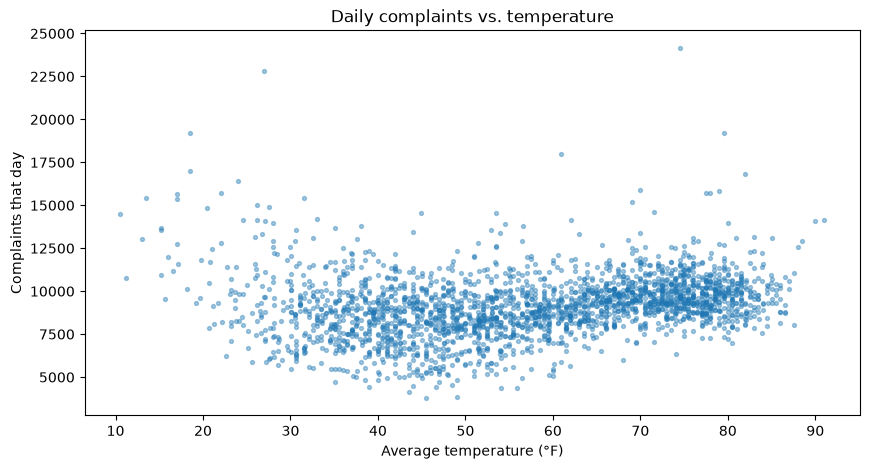

In [276]:
#One row per day: number of complaints and that day's Central Park weather (from the analysis-ready file)
Daily = (Final[Final["COMPLAINT_GROUP"] == "All complaints"].set_index("DATE")
         .rename(columns={"CP_TAVG": "TAVG", "CP_PRCP": "PRCP", "CP_SNOW": "SNOW"})
         [["REQUESTS", "TAVG", "PRCP", "SNOW", "SEASON"]])

#One row per day, one column per complaint type
DailyByType = (Complaints.groupby(["CREATED_DATE", ComplaintType]).size().unstack(fill_value=0)
               .reindex(Daily.index, fill_value=0))   #same days as Daily, in case a day had no requests

#Average temperature vs. number of complaints, one dot per day
Daily.plot.scatter(x="TAVG", y="REQUESTS", s=8, alpha=0.4, figsize=(10, 5),
                   xlabel="Average temperature (°F)", ylabel="Complaints that day", title="Daily complaints vs. temperature")

SEASON  Problem (formerly Complaint Type)
Fall    Illegal Parking                      668916
        Noise - Residential                  632153
        HEAT/HOT WATER                       383088
Spring  Illegal Parking                      780704
        Noise - Residential                  623255
        HEAT/HOT WATER                       327489
Summer  Illegal Parking                      778426
        Noise - Residential                  704175
        Noise - Street/Sidewalk              523838
Winter  HEAT/HOT WATER                       877169
        Illegal Parking                      665353
        Noise - Residential                  578280
dtype: int64

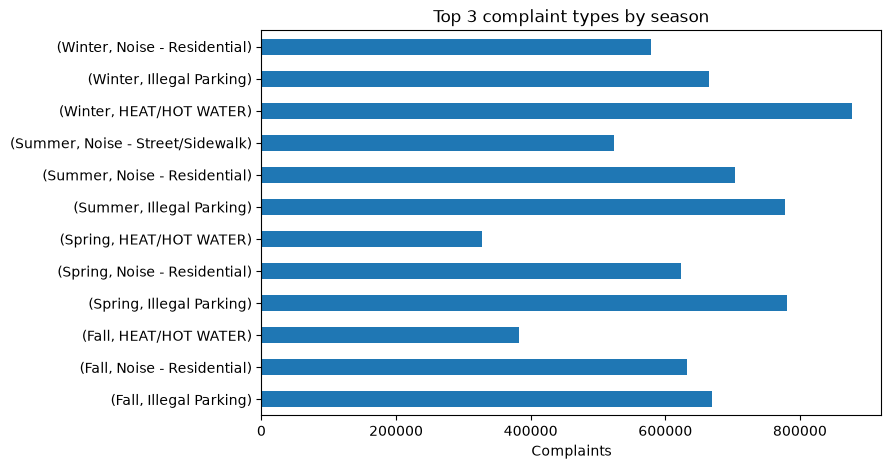

In [277]:
#Top 3 complaint types in each season
SeasonCounts = DailyByType.groupby(Daily["SEASON"]).sum().stack()
TopBySeason = SeasonCounts.groupby(level="SEASON", group_keys=False).nlargest(3)
TopBySeason.plot.barh(figsize=(8, 5), ylabel="", xlabel="Complaints", title="Top 3 complaint types by season")
TopBySeason

<Axes: title={'center': 'Complaints that rise the most on rainy days'}, xlabel='Complaints per day'>

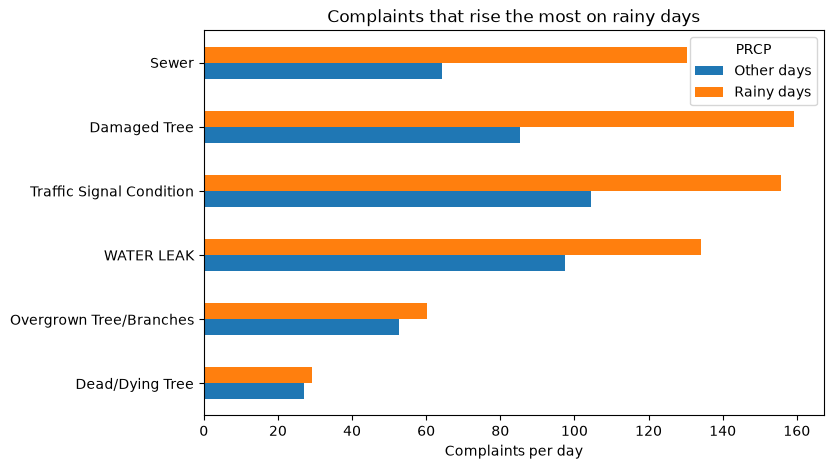

In [278]:
#Average complaints per day on rainy days (0.1 in or more) vs. other days, for the 6 types that rise the most
#Only types with at least 5 complaints a day are included
Rain = DailyByType.groupby(Daily["PRCP"] >= 0.1).mean().T.rename(columns={False: "Other days", True: "Rainy days"})
Rain = Rain[Rain["Other days"] >= 5]
Rain.loc[(Rain["Rainy days"] / Rain["Other days"]).nlargest(6).index[::-1]].plot.barh(ylabel="", figsize=(8, 5), xlabel="Complaints per day", title="Complaints that rise the most on rainy days")

<Axes: title={'center': 'Complaints that rise the most on snowy days'}, xlabel='Complaints per day'>

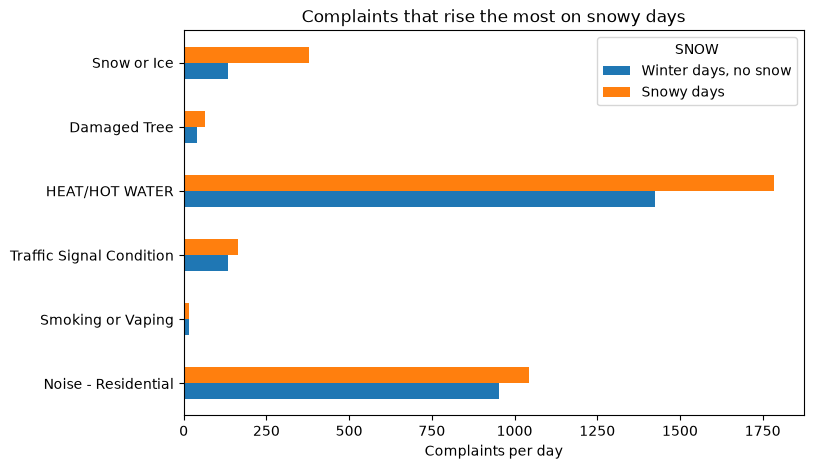

In [279]:
#Same comparison for snowy days, using winter days only so snowy days are compared with other winter days
Winter = Daily["SEASON"] == "Winter"
Snow = DailyByType[Winter].groupby(Daily.loc[Winter, "SNOW"] > 0).mean().T.rename(columns={False: "Winter days, no snow", True: "Snowy days"})
Snow = Snow[Snow["Winter days, no snow"] >= 5]
Snow.loc[(Snow["Snowy days"] / Snow["Winter days, no snow"]).nlargest(6).index[::-1]].plot.barh(ylabel="", figsize=(8, 5), xlabel="Complaints per day", title="Complaints that rise the most on snowy days")